# Rotation Source Separation (RSS) Validation with Source-Structure-Aware Losses

This notebook mirrors every experiment in `rss_validation.ipynb` while comparing the
original zero-lag RSS objective with four source-family-specific objectives. Harmonic
sources use global spectral overlap, filtered noise uses multi-lag cross-correlation,
chirps use time-frequency overlap, and piecewise-transient sources use sparse innovations
and event separation. Both RSS variants receive the same generated scenario, initial
rotation, PSO seed, particle count, and iteration budget. PCA, JADE-ICA, FastICA, and SOBI
continue to receive the same cumulative observer signals. Ground truth is used only after
fitting for evaluation, frame-error diagnostics, case selection, and loss-landscape plots.

Source generation, centering, whitening/rescaling, physical quaternion acquisition,
SO(3) geometry, branch conventions, and the original validation metrics are unchanged.
Angle unwrapping is applied only inside the specialized objectives; reported physical
source angles retain the RSS reconstruction convention.

## 1. Imports and package setup

In [1]:
from dataclasses import asdict, dataclass, replace
from itertools import permutations, product
import json
import math
from pathlib import Path
import time
from types import SimpleNamespace
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

REPO_ROOT = next((candidate for candidate in (Path.cwd(), Path.cwd().parent) if (candidate / 'rss').exists()), None)
if REPO_ROOT is None:
    raise RuntimeError('Could not locate the repository root containing rss/.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from rss import (
    BatchStudyConfig, RSSConfig, SimulationConfig, SuiteCaseSpec,
    build_metrics_frame, build_source_metrics_frame, create_standard_case_specs,
    create_stress_case_specs, export_validation_case_artifacts,
    describe_metric_distributions, generate_family_scenario,
    generate_validation_scenario, run_validation_for_scenario,
    summarize_standard_suite, summarize_stress_suite,
    orthonormality_error,
    source_cross_correlation_matrix,
)
from rss.plotting import (
    plot_loss_history, plot_moving_rotation_geometry, plot_observed_signals, plot_rotation_geometry,
    plot_observer_reconstruction, plot_source_axis_comparison, plot_source_comparison,
)
from bss_baselines import (
    BSSConfig, CorrelationSweepConfig, build_bss_metrics_frame, build_bss_source_metrics_frame,
    build_method_comparison_frames, export_bss_case_artifacts,
    plot_bss_observer_reconstruction, plot_bss_source_comparison,
    plot_method_correlation_curves, plot_method_distribution_grid, plot_method_family_bars,
    plot_method_stress_curves, run_bss_methods_for_scenario,
    run_correlation_sensitivity_sweep,
)
from rss import CorrelationStudyConfig
from rss import (
    RSSResult, compose_source_quaternions, decode_scalar_and_vector,
    integrated_body_angles_to_quaternions, quaternion_error_angles,
    quaternion_reconstruction_loss_torch, quaternions_to_angles,
    quaternions_to_integrated_body_angles, relative_reconstruction_quaternions,
)
from rss.evaluation import evaluate_recovery
from rss.model import decode_scalar_and_vector_torch
from rss.simulation import (
    create_correlation_case_specs, generate_correlation_scenario,
    random_orthonormal_axes,
)
from rss.solver import (
    _decode_scalar_and_vector_batch, _exponential_learning_rates,
    _loss_record, _matrices_from_parameters, _matrix_diagnostics,
    _matrix_from_parameters, _pso_position_step, _resolve_device,
    lagged_cross_correlation_loss,
)
from bss_baselines.correlation_sensitivity import (
    CorrelationCaseOutcome, attach_correlation_columns,
    estimate_correlation_thresholds, paired_method_comparisons,
    summarize_correlation_sensitivity,
)

plt.rcParams['figure.figsize'] = (12, 6)
np.set_printoptions(precision=4, suppress=True)

def display_one_figure(figure):
    """Display exactly one Matplotlib figure, then release it."""
    display(figure)
    plt.close(figure)

SOURCE_ZERO_MEAN_ATOL = 1e-12
FILTERED_NOISE_EDGE_RMS_RATIO_LIMIT = 3.0
SOURCE_SIGNAL_AUDIT = {}

def validate_zero_mean_sources(scenario):
    """Validate zero centering, axis crossing, and stationary-noise edges."""
    source_means = {
        'generated': np.mean(scenario.generated_sources, axis=1),
        'relative': np.mean(scenario.relative_sources, axis=1),
        'recovery': np.mean(scenario.sources, axis=1),
    }
    for label, means in source_means.items():
        if not np.allclose(means, 0.0, rtol=0.0, atol=SOURCE_ZERO_MEAN_ATOL):
            raise RuntimeError(
                f'{scenario.case_id} has nonzero {label} source temporal means: {means.tolist()}'
            )

    active_indices = np.asarray(scenario.active_source_indices, dtype=int)
    active_sources = scenario.sources[active_indices]
    crosses_time_axis = (
        np.min(active_sources, axis=1) < -SOURCE_ZERO_MEAN_ATOL
    ) & (
        np.max(active_sources, axis=1) > SOURCE_ZERO_MEAN_ATOL
    )
    if not np.all(crosses_time_axis):
        failed = active_indices[~crosses_time_axis] + 1
        raise RuntimeError(
            f'{scenario.case_id} sources do not cross the time axis: {failed.tolist()}'
        )

    edge_rms_ratio = np.nan
    if scenario.family == 'filtered_noise':
        sample_count = active_sources.shape[1]
        edge_count = min(max(1, sample_count // 10), (sample_count - 1) // 2)
        interior = active_sources[:, edge_count:-edge_count]
        interior_rms = np.sqrt(np.mean(np.square(interior), axis=1))
        leading_rms = np.sqrt(np.mean(np.square(active_sources[:, :edge_count]), axis=1))
        trailing_rms = np.sqrt(np.mean(np.square(active_sources[:, -edge_count:]), axis=1))
        edge_rms_ratio = float(np.max(
            np.concatenate((leading_rms / interior_rms, trailing_rms / interior_rms))
        ))
        if edge_rms_ratio > FILTERED_NOISE_EDGE_RMS_RATIO_LIMIT:
            raise RuntimeError(
                f'{scenario.case_id} has a filtered-noise edge transient: '
                f'edge/interior RMS ratio={edge_rms_ratio:.3f}'
            )

    SOURCE_SIGNAL_AUDIT[scenario.case_id] = {
        'case_id': scenario.case_id,
        'family': scenario.family,
        'active_source_count': len(active_indices),
        'max_abs_temporal_mean': max(
            float(np.max(np.abs(means))) for means in source_means.values()
        ),
        'all_active_sources_cross_time_axis': bool(np.all(crosses_time_axis)),
        'filtered_noise_max_edge_rms_ratio': edge_rms_ratio,
    }
    return source_means

REPO_ROOT

PosixPath('.')

## 1A. Notebook-local specialized loss and PSO implementation

The public `rss` and `bss_baselines` packages are not modified. The notebook reuses the
current solver's private geometry, decoding, learning-rate, matrix-diagnostic, and clamped
PSO-boundary helpers, while providing a local loss dispatcher and PSO orchestration. This
intentionally couples the notebook to the current solver implementation so that the paired
experiments preserve its exact numerical behavior.

In [2]:
PAIR_INDICES = ((0, 1), (0, 2), (1, 2))
LOSS_CORR_ZERO_LAG = 'corr_zero_lag'
LOSS_HARMONIC = 'harmonic_spectral_overlap'
LOSS_FILTERED = 'filtered_multilag_cross_correlation'
LOSS_CHIRP = 'chirp_time_frequency_overlap'
LOSS_PIECEWISE = 'piecewise_sparse_innovation'
FAMILY_LOSS_MODES = {
    'harmonic': LOSS_HARMONIC,
    'filtered_noise': LOSS_FILTERED,
    'chirp_modulated': LOSS_CHIRP,
    'piecewise_transient': LOSS_PIECEWISE,
}


@dataclass(frozen=True)
class SpecializedLossConfig:
    bad_loss: float = 1e6
    variance_floor: float = 1e-12
    numerical_eps: float = 1e-12
    unwrap_for_loss: bool = True
    analysis_band_hz: tuple[float, float] = (0.0, 5.0)
    harmonic_nperseg: int = 256
    harmonic_overlap_fraction: float = 0.5
    harmonic_gamma: float = 1.0
    filtered_max_lag: int = 100
    chirp_nperseg: int = 128
    chirp_noverlap: int = 96
    chirp_nfft: int = 256
    chirp_energy_weighted: bool = False
    piecewise_lambda: float = 0.5

    def __post_init__(self):
        finite_positive = {
            'bad_loss': self.bad_loss,
            'variance_floor': self.variance_floor,
            'numerical_eps': self.numerical_eps,
            'harmonic_gamma': self.harmonic_gamma,
        }
        for name, value in finite_positive.items():
            if not math.isfinite(float(value)) or float(value) <= 0.0:
                raise ValueError(f'{name} must be finite and > 0.')
        low, high = map(float, self.analysis_band_hz)
        if not (math.isfinite(low) and math.isfinite(high) and 0.0 <= low < high):
            raise ValueError('analysis_band_hz must contain finite increasing nonnegative bounds.')
        if int(self.harmonic_nperseg) < 4:
            raise ValueError('harmonic_nperseg must be >= 4.')
        if not 0.0 <= float(self.harmonic_overlap_fraction) < 1.0:
            raise ValueError('harmonic_overlap_fraction must lie in [0, 1).')
        if int(self.filtered_max_lag) < 0:
            raise ValueError('filtered_max_lag must be >= 0.')
        if int(self.chirp_nperseg) < 4:
            raise ValueError('chirp_nperseg must be >= 4.')
        if not 0 <= int(self.chirp_noverlap) < int(self.chirp_nperseg):
            raise ValueError('chirp_noverlap must lie in [0, chirp_nperseg).')
        if int(self.chirp_nfft) < int(self.chirp_nperseg):
            raise ValueError('chirp_nfft must be >= chirp_nperseg.')
        if not 0.0 <= float(self.piecewise_lambda) <= 1.0:
            raise ValueError('piecewise_lambda must lie in [0, 1].')


@dataclass(frozen=True)
class SpecializedRSSConfigView:
    base_config: RSSConfig
    loss_mode: str
    specialized_loss_config: SpecializedLossConfig

    @property
    def loss_type(self):
        return self.loss_mode

    def __getattr__(self, name):
        return getattr(self.base_config, name)


@dataclass(frozen=True)
class SpecializedFitOutput:
    rss_result: RSSResult
    loss_value: float
    diagnostics: dict[str, object]


@dataclass(frozen=True)
class ExperimentRun:
    validation: object
    method_key: str
    method_label: str
    runtime_seconds: float
    raw_frame_error_rad: float
    aligned_frame_error_rad: float
    success: bool
    loss_config: dict[str, object]
    diagnostics: dict[str, object]


def _next_power_of_two(value):
    return 1 << max(0, int(value - 1).bit_length())


def _unwrap_rows_torch(values):
    if values.shape[-1] < 2:
        return values
    differences = values[..., 1:] - values[..., :-1]
    wrapped = torch.atan2(torch.sin(differences), torch.cos(differences))
    return torch.cat((values[..., :1], values[..., :1] + torch.cumsum(wrapped, dim=-1)), dim=-1)


def _pairwise_bhattacharyya(distributions):
    pair_values = torch.stack(
        [torch.sum(torch.sqrt(distributions[..., i, :] * distributions[..., j, :]), dim=-1)
         for i, j in PAIR_INDICES],
        dim=-1,
    )
    return torch.mean(pair_values, dim=-1), pair_values


def _one_sided_windowed_power(values, fs, nperseg, noverlap, nfft):
    sample_count = int(values.shape[-1])
    segment = min(int(nperseg), sample_count)
    if segment < 4:
        raise ValueError('Spectral losses require at least four samples.')
    overlap = min(int(noverlap), segment - 1)
    hop = segment - overlap
    fft_count = max(int(nfft), segment)
    frames = values.unfold(-1, segment, hop)
    window = torch.hann_window(
        segment, periodic=True, dtype=values.dtype, device=values.device,
    )
    transformed = torch.fft.rfft(frames * window, n=fft_count, dim=-1)
    power = transformed.real.square() + transformed.imag.square()
    scale = float(fs) * torch.sum(window.square())
    power = power / torch.clamp(scale, min=torch.finfo(values.dtype).tiny)
    if fft_count % 2 == 0 and power.shape[-1] > 2:
        power[..., 1:-1] *= 2.0
    elif power.shape[-1] > 1:
        power[..., 1:] *= 2.0
    frequencies = torch.fft.rfftfreq(fft_count, d=1.0 / float(fs), device=values.device)
    return power, frequencies, segment, overlap, hop, fft_count


def _harmonic_loss(values, fs, config, diagnostics):
    nperseg = min(int(config.harmonic_nperseg), int(values.shape[-1]))
    noverlap = int(math.floor(float(config.harmonic_overlap_fraction) * nperseg))
    nfft = _next_power_of_two(nperseg)
    frame_power, frequencies, nperseg, noverlap, hop, nfft = _one_sided_windowed_power(
        values, fs, nperseg, noverlap, nfft,
    )
    psd = torch.mean(frame_power, dim=-2)
    low, high = config.analysis_band_hz
    mask = (frequencies >= float(low)) & (frequencies <= float(high))
    if not bool(torch.any(mask)):
        raise ValueError('The harmonic analysis band contains no FFT bins.')
    band_psd = psd[..., mask]
    shaped = torch.pow(band_psd + float(config.numerical_eps), float(config.harmonic_gamma))
    distributions = shaped / torch.clamp(
        torch.sum(shaped, dim=-1, keepdim=True), min=float(config.numerical_eps),
    )
    loss, pairs = _pairwise_bhattacharyya(distributions)
    if diagnostics:
        return loss, {
            'frequencies_hz': frequencies[mask], 'psd': band_psd,
            'spectral_distributions': distributions,
            'pair_overlaps': pairs, 'nperseg': nperseg,
            'noverlap': noverlap, 'nfft': nfft,
        }, torch.ones_like(loss, dtype=torch.bool)
    return loss, {}, torch.ones_like(loss, dtype=torch.bool)


def _filtered_loss(values, config, diagnostics):
    sample_count = int(values.shape[-1])
    maximum_lag = min(int(config.filtered_max_lag), sample_count // 4, sample_count - 1)
    lags = torch.arange(-maximum_lag, maximum_lag + 1, device=values.device, dtype=torch.long)
    lag_float = lags.to(dtype=values.dtype)
    weights = 1.0 - torch.abs(lag_float) / float(maximum_lag + 1)
    weights = weights / torch.sum(weights)
    convolution_nfft = _next_power_of_two(2 * sample_count - 1)
    spectra = torch.fft.rfft(values, n=convolution_nfft, dim=-1)
    reversed_spectra = torch.fft.rfft(torch.flip(values, dims=(-1,)), n=convolution_nfft, dim=-1)
    squares = values.square()
    prefix = torch.cat((torch.zeros_like(squares[..., :1]), torch.cumsum(squares, dim=-1)), dim=-1)
    x_start = torch.clamp(-lags, min=0)
    x_stop = sample_count - torch.clamp(lags, min=0)
    y_start = torch.clamp(lags, min=0)
    y_stop = sample_count - torch.clamp(-lags, min=0)
    correlations = []
    pair_energies = []
    for first, second in PAIR_INDICES:
        convolution = torch.fft.irfft(
            spectra[..., second, :] * reversed_spectra[..., first, :],
            n=convolution_nfft,
            dim=-1,
        )[..., :2 * sample_count - 1]
        numerators = convolution[..., lags + sample_count - 1]
        first_prefix = prefix[..., first, :]
        second_prefix = prefix[..., second, :]
        first_energy = first_prefix[..., x_stop] - first_prefix[..., x_start]
        second_energy = second_prefix[..., y_stop] - second_prefix[..., y_start]
        denominator = torch.sqrt(torch.clamp(first_energy * second_energy, min=0.0))
        rho = numerators / (denominator + float(config.numerical_eps))
        correlations.append(rho)
        pair_energies.append(torch.sum(weights * rho.square(), dim=-1))
    correlations = torch.stack(correlations, dim=-2)
    pair_energies = torch.stack(pair_energies, dim=-1)
    loss = torch.mean(pair_energies, dim=-1)
    detail = {
        'lags': lags, 'lag_weights': weights, 'pair_correlations': correlations,
        'pair_energies': pair_energies,
    } if diagnostics else {}
    return loss, detail, torch.ones_like(loss, dtype=torch.bool)


def _chirp_loss(values, fs, config, diagnostics):
    frame_power, frequencies, nperseg, noverlap, hop, nfft = _one_sided_windowed_power(
        values, fs, config.chirp_nperseg, config.chirp_noverlap, config.chirp_nfft,
    )
    low, high = config.analysis_band_hz
    mask = (frequencies >= float(low)) & (frequencies <= float(high))
    if not bool(torch.any(mask)):
        raise ValueError('The chirp analysis band contains no FFT bins.')
    band_power = frame_power[..., mask]
    denominator = torch.sum(band_power + float(config.numerical_eps), dim=-1, keepdim=True)
    distributions = (band_power + float(config.numerical_eps)) / denominator
    frame_overlaps = torch.stack(
        [torch.sum(torch.sqrt(distributions[..., i, :, :] * distributions[..., j, :, :]), dim=-1)
         for i, j in PAIR_INDICES],
        dim=-1,
    )
    if config.chirp_energy_weighted:
        total_energy = torch.sum(band_power, dim=(-3, -1))
        frame_weights = total_energy / torch.clamp(
            torch.sum(total_energy, dim=-1, keepdim=True), min=float(config.numerical_eps),
        )
    else:
        frame_weights = torch.full_like(frame_overlaps[..., 0], 1.0 / frame_overlaps.shape[-2])
    pair_overlaps = torch.sum(frame_weights.unsqueeze(-1) * frame_overlaps, dim=-2)
    loss = torch.mean(pair_overlaps, dim=-1)
    detail = {}
    if diagnostics:
        band_frequencies = frequencies[mask]
        ridges = torch.sum(distributions * band_frequencies, dim=-1)
        frame_times = (
            torch.arange(frame_power.shape[-2], dtype=values.dtype, device=values.device) * hop
            + 0.5 * nperseg
        ) / float(fs)
        detail = {
            'frequencies_hz': band_frequencies, 'frame_times_seconds': frame_times,
            'tf_power': band_power, 'tf_distributions': distributions,
            'frame_overlaps': frame_overlaps, 'pair_overlaps': pair_overlaps,
            'ridge_centroids_hz': ridges, 'frame_weights': frame_weights,
            'nperseg': nperseg, 'noverlap': noverlap, 'nfft': nfft,
        }
    return loss, detail, torch.ones_like(loss, dtype=torch.bool)


def _piecewise_loss(values, config, diagnostics):
    if values.shape[-1] < 3:
        raise ValueError('The piecewise loss requires at least three samples.')
    innovations = values[..., 2:] - 2.0 * values[..., 1:-1] + values[..., :-2]
    envelopes = torch.abs(innovations)
    count = int(innovations.shape[-1])
    l1 = torch.sum(torch.abs(innovations), dim=-1)
    l2 = torch.linalg.vector_norm(innovations, dim=-1)
    valid = torch.all(l2 > float(config.numerical_eps), dim=-1)
    root = math.sqrt(float(count))
    hoyer = (root - l1 / (l2 + float(config.numerical_eps))) / max(root - 1.0, config.numerical_eps)
    hoyer = torch.clamp(hoyer, min=0.0, max=1.0)
    sparse_loss = 1.0 - torch.mean(hoyer, dim=-1)
    event_overlaps = torch.stack(
        [torch.sum(envelopes[..., i, :] * envelopes[..., j, :], dim=-1)
         / (l2[..., i] * l2[..., j] + float(config.numerical_eps))
         for i, j in PAIR_INDICES],
        dim=-1,
    )
    event_loss = torch.mean(event_overlaps, dim=-1)
    weight = float(config.piecewise_lambda)
    loss = weight * sparse_loss + (1.0 - weight) * event_loss
    detail = {
        'innovations': innovations, 'event_envelopes': envelopes,
        'hoyer_sparsities': hoyer, 'sparsity_loss': sparse_loss,
        'pair_event_overlaps': event_overlaps, 'event_loss': event_loss,
    } if diagnostics else {}
    return loss, detail, valid


def _specialized_loss_tensor(sources, fs, loss_mode, config, diagnostics=False):
    values = sources
    if values.ndim not in (2, 3) or values.shape[-2] != 3:
        raise ValueError('sources must have shape (3, N) or (P, 3, N).')
    if values.shape[-1] < 4:
        raise ValueError('Specialized RSS losses require at least four samples.')
    if not math.isfinite(float(fs)) or float(fs) <= 0.0:
        raise ValueError('fs must be finite and > 0.')
    finite = torch.all(torch.isfinite(values), dim=(-2, -1))
    safe = torch.nan_to_num(values, nan=0.0, posinf=0.0, neginf=0.0)
    if loss_mode == LOSS_CORR_ZERO_LAG:
        loss = lagged_cross_correlation_loss(safe, (0,), eps=float(config.numerical_eps))
        return torch.where(finite, loss, torch.full_like(loss, float(config.bad_loss))), {}, finite
    if config.unwrap_for_loss:
        safe = _unwrap_rows_torch(safe)
    safe = safe - torch.mean(safe, dim=-1, keepdim=True)
    variances = torch.mean(safe.square(), dim=-1)
    valid = finite & torch.all(variances >= float(config.variance_floor), dim=-1)
    if loss_mode == LOSS_HARMONIC:
        loss, detail, extra_valid = _harmonic_loss(safe, fs, config, diagnostics)
    elif loss_mode == LOSS_FILTERED:
        loss, detail, extra_valid = _filtered_loss(safe, config, diagnostics)
    elif loss_mode == LOSS_CHIRP:
        loss, detail, extra_valid = _chirp_loss(safe, fs, config, diagnostics)
    elif loss_mode == LOSS_PIECEWISE:
        loss, detail, extra_valid = _piecewise_loss(safe, config, diagnostics)
    else:
        raise ValueError(f'Unsupported specialized loss mode: {loss_mode!r}.')
    valid = valid & extra_valid & torch.isfinite(loss)
    guarded = torch.where(valid, loss, torch.full_like(loss, float(config.bad_loss)))
    if diagnostics:
        detail = dict(detail)
        detail['centered_unwrapped_sources'] = safe
        detail['row_variances'] = variances
        detail['valid_candidate'] = valid
    return guarded, detail, valid


def _to_numpy_diagnostics(value):
    if isinstance(value, torch.Tensor):
        array = value.detach().cpu().numpy()
        return float(array) if array.ndim == 0 else array
    if isinstance(value, dict):
        return {key: _to_numpy_diagnostics(item) for key, item in value.items()}
    return value


def compute_specialized_loss(sources, fs, loss_mode, loss_cfg, return_diagnostics=False):
    is_tensor = isinstance(sources, torch.Tensor)
    tensor = sources if is_tensor else torch.as_tensor(sources, dtype=torch.float64)
    loss, diagnostics, _ = _specialized_loss_tensor(
        tensor, fs, loss_mode, loss_cfg, diagnostics=return_diagnostics,
    )
    if is_tensor:
        return (loss, diagnostics) if return_diagnostics else loss
    converted_loss = _to_numpy_diagnostics(loss)
    converted_diagnostics = _to_numpy_diagnostics(diagnostics)
    return (converted_loss, converted_diagnostics) if return_diagnostics else converted_loss


PROPER_SIGNED_PERMUTATIONS = tuple(
    signed
    for permutation in permutations(range(3))
    for signs in product((-1.0, 1.0), repeat=3)
    for signed in (np.diag(signs) @ np.eye(3)[list(permutation)],)
    if np.linalg.det(signed) > 0.0
)
assert len(PROPER_SIGNED_PERMUTATIONS) == 24


def so3_geodesic_error(first, second):
    relative = np.asarray(first, dtype=float).T @ np.asarray(second, dtype=float)
    cosine = np.clip((np.trace(relative) - 1.0) / 2.0, -1.0, 1.0)
    return float(np.arccos(cosine))


def symmetry_aligned_so3_error(estimate, truth):
    return min(so3_geodesic_error(symmetry @ estimate, truth) for symmetry in PROPER_SIGNED_PERMUTATIONS)


def _specialized_loss_terms(source_angles, recovery_matrices, observer_quaternions, view, fs):
    separation_loss = compute_specialized_loss(
        source_angles, fs, view.loss_mode, view.specialized_loss_config,
    )
    identity = torch.eye(3, dtype=recovery_matrices.dtype, device=recovery_matrices.device)
    if recovery_matrices.ndim == 3:
        identity = identity.unsqueeze(0)
        gram_error = recovery_matrices @ recovery_matrices.transpose(1, 2) - identity
        orthogonality_loss = torch.sum(gram_error.square(), dim=(1, 2)) / 3.0
    else:
        gram_error = recovery_matrices @ recovery_matrices.T - identity
        orthogonality_loss = torch.sum(gram_error.square()) / 3.0
    if float(view.reconstruction_weight) == 0.0:
        reconstruction_loss = torch.zeros_like(separation_loss)
    else:
        reconstruction_loss, _, _ = quaternion_reconstruction_loss_torch(
            source_angles, recovery_matrices, observer_quaternions, eps=float(view.eps),
        )
    total = (
        float(view.separation_weight) * separation_loss
        + float(view.orthogonality_weight) * orthogonality_loss
        + float(view.reconstruction_weight) * reconstruction_loss
    )
    return total, {
        'separation_loss': separation_loss,
        'orthogonality_loss': orthogonality_loss,
        'reconstruction_loss': reconstruction_loss,
    }


def fit_specialized_rss(observer_angles, rss_cfg, loss_cfg, sample_interval_seconds):
    if rss_cfg.optimizer != 'pso':
        raise ValueError("Notebook-local specialized losses require optimizer='pso'.")
    if rss_cfg.matrix_parameterization != 'so3':
        raise ValueError("Notebook-local specialized losses require matrix_parameterization='so3'.")
    if rss_cfg.observer_signal_model != 'integrated_body_rotation':
        raise ValueError("Notebook-local specialized losses require integrated body rotations.")
    interval = float(sample_interval_seconds)
    if not math.isfinite(interval) or interval <= 0.0:
        raise ValueError('sample_interval_seconds must be finite and > 0.')
    fs = 1.0 / interval
    mode = str(loss_cfg['mode']) if isinstance(loss_cfg, dict) else FAMILY_LOSS_MODES[str(loss_cfg)]
    config = loss_cfg['config'] if isinstance(loss_cfg, dict) else DEFAULT_SPECIALIZED_LOSS_CONFIG
    view = SpecializedRSSConfigView(rss_cfg, mode, config)
    angles = np.asarray(observer_angles, dtype=float)
    if angles.ndim != 2:
        raise ValueError('observer_angles must be a 2D array.')
    if angles.shape[0] != 3 and angles.shape[1] == 3:
        angles = angles.T
    if angles.shape[0] != 3 or not np.isfinite(angles).all():
        raise ValueError('observer_angles must be finite with shape (3, T) or (T, 3).')
    observer_quaternions = integrated_body_angles_to_quaternions(
        angles, eps=float(rss_cfg.quaternion_eps),
    )
    observer_scalar = observer_quaternions[:, 0]
    observer_vector = observer_quaternions[:, 1:].T
    device = _resolve_device(rss_cfg.device)
    dtype = torch.float64
    scalar_tensor = torch.as_tensor(observer_scalar, dtype=dtype, device=device)
    vector_tensor = torch.as_tensor(observer_vector, dtype=dtype, device=device)
    observer_tensor = torch.as_tensor(observer_quaternions, dtype=dtype, device=device)
    initial_parameters = torch.as_tensor(
        rss_cfg.resolved_initial_parameters, dtype=dtype, device=device,
    )

    def evaluate_one(parameters):
        matrix = _matrix_from_parameters(parameters, rss_cfg.matrix_parameterization)
        source_vector = matrix @ vector_tensor
        source_angles, _ = decode_scalar_and_vector_torch(
            scalar_tensor, source_vector, eps=float(rss_cfg.quaternion_eps),
        )
        return _specialized_loss_terms(source_angles, matrix, observer_tensor, view, fs)

    with torch.no_grad():
        initial_total, initial_terms = evaluate_one(initial_parameters)
    initial_loss = float(initial_total.detach().cpu())
    if not math.isfinite(initial_loss):
        raise FloatingPointError('Specialized RSS loss became non-finite at epoch 0.')
    reference = max(initial_loss, float(rss_cfg.eps))
    initial_components = {name: float(value.detach().cpu()) for name, value in initial_terms.items()}
    history = [_loss_record(
        epoch=0, raw_total=initial_loss,
        separation_loss=initial_components['separation_loss'],
        orthogonality_loss=initial_components['orthogonality_loss'],
        reconstruction_loss=initial_components['reconstruction_loss'],
        learning_rate=None, reference=reference, config=view,
    )]
    generator = torch.Generator(device=device)
    generator.manual_seed(int(rss_cfg.pso_seed))
    particle_count = int(rss_cfg.pso_swarm_size)
    lower, upper = rss_cfg.resolved_pso_bounds
    positions = lower + (upper - lower) * torch.rand(
        (particle_count, 3), dtype=dtype, device=device, generator=generator,
    )
    positions[0] = initial_parameters
    velocities = torch.zeros_like(positions)
    personal_best_positions = positions.clone()
    personal_best_losses = torch.full((particle_count,), float('inf'), dtype=dtype, device=device)
    global_best_parameters = initial_parameters.clone()
    global_best_loss = initial_loss
    global_best_normalized_loss = float(history[0]['normalized_total_loss'])
    global_best_components = initial_components.copy()
    best_epoch = 0
    movement_rates = _exponential_learning_rates(
        float(rss_cfg.learning_rate), float(rss_cfg.learning_rate_end),
        max(int(rss_cfg.epochs) - 1, 0),
    )
    last_rate = None
    for epoch in range(1, int(rss_cfg.epochs) + 1):
        with torch.no_grad():
            matrices = _matrices_from_parameters(positions, rss_cfg.matrix_parameterization)
            source_vectors = torch.einsum('pij,jt->pit', matrices, vector_tensor)
            source_angles = _decode_scalar_and_vector_batch(
                scalar_tensor, source_vectors, eps=float(rss_cfg.quaternion_eps),
            )
            raw_totals, terms = _specialized_loss_terms(
                source_angles, matrices, observer_tensor, view, fs,
            )
        if not bool(torch.isfinite(raw_totals).all()):
            raise FloatingPointError(f'Specialized particle loss became non-finite at epoch {epoch}.')
        improved = raw_totals < personal_best_losses
        personal_best_losses = torch.where(improved, raw_totals, personal_best_losses)
        personal_best_positions = torch.where(improved.unsqueeze(1), positions, personal_best_positions)
        current_index = int(torch.argmin(raw_totals).detach().cpu())
        current_loss = float(raw_totals[current_index].detach().cpu())
        if current_loss < global_best_loss:
            global_best_loss = current_loss
            global_best_parameters = positions[current_index].clone()
            global_best_components = {
                name: float(values[current_index].detach().cpu()) for name, values in terms.items()
            }
            global_best_normalized_loss = global_best_loss / reference
            best_epoch = epoch
        history.append(_loss_record(
            epoch=epoch, raw_total=global_best_loss,
            separation_loss=global_best_components['separation_loss'],
            orthogonality_loss=global_best_components['orthogonality_loss'],
            reconstruction_loss=global_best_components['reconstruction_loss'],
            learning_rate=last_rate, reference=reference, config=view,
        ))
        if epoch == int(rss_cfg.epochs):
            break
        random_cognitive = torch.rand(positions.shape, dtype=dtype, device=device, generator=generator)
        random_social = torch.rand(positions.shape, dtype=dtype, device=device, generator=generator)
        velocities = (
            float(rss_cfg.pso_inertia) * velocities
            + float(rss_cfg.pso_cognitive) * random_cognitive * (personal_best_positions - positions)
            + float(rss_cfg.pso_social) * random_social * (global_best_parameters.unsqueeze(0) - positions)
        )
        movement_rate = movement_rates[epoch - 1]
        positions, velocities = _pso_position_step(
            positions, velocities, movement_rate, lower=lower, upper=upper,
        )
        last_rate = movement_rate

    best_parameters = global_best_parameters.detach().cpu().numpy().copy()
    recovery_matrix = np.asarray(
        _matrix_from_parameters(best_parameters, rss_cfg.matrix_parameterization), dtype=float,
    )
    source_coefficients = recovery_matrix @ observer_vector
    source_angles, source_quaternions = decode_scalar_and_vector(
        observer_scalar, source_coefficients, eps=float(rss_cfg.quaternion_eps),
    )
    composed = compose_source_quaternions(
        source_angles, recovery_matrix, eps=float(rss_cfg.quaternion_eps),
    )
    relative = relative_reconstruction_quaternions(
        composed, observer_quaternions, eps=float(rss_cfg.quaternion_eps),
    )
    reconstructed_observer_angles = quaternions_to_integrated_body_angles(
        composed, eps=float(rss_cfg.quaternion_eps),
    )
    reconstruction_errors = quaternion_error_angles(relative, eps=float(rss_cfg.quaternion_eps))
    loss_value, diagnostics = compute_specialized_loss(
        source_angles, fs, mode, config, return_diagnostics=True,
    )
    applied_rates = tuple(float(row['learning_rate']) for row in history if row['learning_rate'] is not None)
    rss_result = RSSResult(
        config=view, optimizer_name='pso', observer_angles=angles,
        observer_scalar=observer_scalar, observer_quaternions=observer_quaternions,
        observer_coefficients=observer_vector, source_angles=source_angles,
        source_quaternions=source_quaternions, source_coefficients=source_coefficients,
        composed_source_quaternions=composed,
        relative_reconstruction_quaternions=relative,
        reconstructed_observer_angles=reconstructed_observer_angles,
        reconstructed_observer_coefficients=composed[:, 1:].T,
        reconstruction_mean_error_rad=float(np.mean(reconstruction_errors)),
        reconstruction_max_error_rad=float(np.max(reconstruction_errors)),
        recovery_matrix=recovery_matrix, optimized_parameters=best_parameters,
        optimized_weights=best_parameters, loss_history=tuple(history),
        sample_interval_seconds=interval, applied_learning_rates=applied_rates,
        initial_loss=initial_loss, best_loss=float(global_best_loss),
        terminal_loss=float(history[-1]['total_loss']),
        loss_normalization_reference=reference,
        normalized_initial_loss=float(history[0]['normalized_total_loss']),
        normalized_best_loss=float(global_best_normalized_loss),
        normalized_terminal_loss=float(history[-1]['normalized_total_loss']),
        best_epoch=int(best_epoch), stop_reason='max_epochs',
        matrix_diagnostics=_matrix_diagnostics(recovery_matrix, eps=float(rss_cfg.eps)),
    )
    return SpecializedFitOutput(rss_result, float(loss_value), diagnostics)


def _augment_run_metrics(validation, runtime_seconds, raw_error, aligned_error, success):
    validation.metrics.update({
        'runtime_seconds': float(runtime_seconds),
        'so3_frame_error_rad': float(raw_error),
        'so3_frame_error_deg': float(np.degrees(raw_error)),
        'so3_frame_error_aligned_rad': float(aligned_error),
        'so3_frame_error_aligned_deg': float(np.degrees(aligned_error)),
        'reconstruction_success': bool(success),
        'reconstruction_success_threshold_deg': 5.0,
    })


def run_specialized_validation_for_scenario(scenario, rss_cfg, loss_cfg, loss_mode=None):
    times = np.asarray(scenario.time_seconds, dtype=float)
    interval = float(np.median(np.diff(times)))
    mode = FAMILY_LOSS_MODES[scenario.family] if loss_mode is None else str(loss_mode)
    started = time.perf_counter()
    fit = fit_specialized_rss(
        scenario.observations, rss_cfg, {'mode': mode, 'config': loss_cfg}, interval,
    )
    validation = evaluate_recovery(scenario, fit.rss_result)
    runtime = time.perf_counter() - started
    raw_error = so3_geodesic_error(fit.rss_result.recovery_matrix, scenario.mixing_matrix)
    aligned_error = symmetry_aligned_so3_error(fit.rss_result.recovery_matrix, scenario.mixing_matrix)
    success = bool(np.degrees(aligned_error) <= 5.0)
    _augment_run_metrics(validation, runtime, raw_error, aligned_error, success)
    validation.metrics['specialized_loss_value'] = fit.loss_value
    pair_values = fit.diagnostics.get('pair_overlaps')
    if pair_values is None:
        pair_values = fit.diagnostics.get('pair_energies')
    if pair_values is None:
        pair_values = fit.diagnostics.get('pair_event_overlaps')
    if pair_values is not None:
        for label, value in zip(('12', '13', '23'), np.asarray(pair_values).reshape(-1)[:3]):
            validation.metrics[f'specialized_pair_component_{label}'] = float(value)
    return ExperimentRun(
        validation, 'rss_specialized', 'RSS specialized', runtime,
        raw_error, aligned_error, success,
        {'mode': mode, **asdict(loss_cfg), 'pso_seed': int(rss_cfg.pso_seed)},
        fit.diagnostics,
    )


def run_zero_lag_validation_for_scenario(scenario, rss_cfg):
    started = time.perf_counter()
    validation = run_validation_for_scenario(scenario, rss_cfg)
    runtime = time.perf_counter() - started
    raw_error = so3_geodesic_error(validation.rss_result.recovery_matrix, scenario.mixing_matrix)
    aligned_error = symmetry_aligned_so3_error(validation.rss_result.recovery_matrix, scenario.mixing_matrix)
    success = bool(np.degrees(aligned_error) <= 5.0)
    _augment_run_metrics(validation, runtime, raw_error, aligned_error, success)
    return ExperimentRun(
        validation, 'rss_corr_baseline', 'RSS zero-lag', runtime,
        raw_error, aligned_error, success,
        {'mode': LOSS_CORR_ZERO_LAG, 'lags': [0], 'pso_seed': int(rss_cfg.pso_seed)}, {},
    )


def run_paired_rss_for_scenario(scenario, rss_cfg, loss_cfg):
    baseline = run_zero_lag_validation_for_scenario(scenario, rss_cfg)
    specialized = run_specialized_validation_for_scenario(scenario, rss_cfg, loss_cfg)
    return baseline, specialized


def _json_safe_notebook(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {str(key): _json_safe_notebook(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [_json_safe_notebook(item) for item in value]
    if isinstance(value, float) and not math.isfinite(value):
        return None
    return value


def export_experiment_run(run, output_dir, include_plots=True):
    output = Path(output_dir)
    payload = export_validation_case_artifacts(
        run.validation, output, include_plots=include_plots,
    )
    metadata = {
        'method_key': run.method_key, 'method_label': run.method_label,
        'runtime_seconds': run.runtime_seconds,
        'so3_frame_error_rad': run.raw_frame_error_rad,
        'so3_frame_error_aligned_rad': run.aligned_frame_error_rad,
        'reconstruction_success': run.success,
        'success_threshold_aligned_frame_error_deg': 5.0,
        'loss_config': run.loss_config,
    }
    (output / 'run_metadata.json').write_text(
        json.dumps(_json_safe_notebook(metadata), indent=2, allow_nan=False), encoding='utf-8',
    )
    arrays = {
        key: np.asarray(value)
        for key, value in run.diagnostics.items()
        if isinstance(value, np.ndarray)
    }
    arrays['loss_config_json'] = np.asarray(json.dumps(_json_safe_notebook(run.loss_config)))
    np.savez_compressed(output / 'loss_diagnostics.npz', **arrays)
    return payload


def build_paired_rss_frame(baseline_runs, specialized_runs):
    baseline = build_metrics_frame([run.validation for run in baseline_runs]).add_suffix('_corr')
    specialized = build_metrics_frame([run.validation for run in specialized_runs]).add_suffix('_specialized')
    merged = baseline.merge(
        specialized,
        left_on=['case_id_corr', 'seed_corr'],
        right_on=['case_id_specialized', 'seed_specialized'],
        validate='one_to_one',
    )
    merged['case_id'] = merged['case_id_specialized']
    merged['family'] = merged['family_specialized']
    merged['delta_abs_correlation'] = (
        merged['mean_abs_source_correlation_specialized']
        - merged['mean_abs_source_correlation_corr']
    )
    merged['delta_rmse_rad'] = (
        merged['mean_source_rmse_specialized'] - merged['mean_source_rmse_corr']
    )
    merged['delta_so3_frame_error_rad'] = (
        merged['so3_frame_error_rad_specialized'] - merged['so3_frame_error_rad_corr']
    )
    merged['delta_so3_frame_error_aligned_rad'] = (
        merged['so3_frame_error_aligned_rad_specialized']
        - merged['so3_frame_error_aligned_rad_corr']
    )
    return merged


def plot_structural_diagnostic(run, title=None):
    diagnostics = run.diagnostics
    family = run.validation.scenario.family
    figure, axes = plt.subplots(1, 3, figsize=(16, 4.5), squeeze=False)
    axes = axes.ravel()
    if family == 'harmonic':
        frequencies = diagnostics['frequencies_hz']
        values = diagnostics['spectral_distributions']
        for index in range(3):
            axes[index].plot(frequencies, values[index])
            axes[index].set_xlabel('Frequency (Hz)')
            axes[index].set_ylabel('Normalized PSD')
    elif family == 'filtered_noise':
        lags = diagnostics['lags']
        for axis, values, pair in zip(axes, diagnostics['pair_correlations'], ('1-2', '1-3', '2-3')):
            axis.plot(lags, values)
            axis.set_xlabel('Lag (samples)')
            axis.set_ylabel(f'Correlation {pair}')
    elif family == 'chirp_modulated':
        times = diagnostics['frame_times_seconds']
        frequencies = diagnostics['frequencies_hz']
        for index in range(3):
            axes[index].pcolormesh(
                times, frequencies, diagnostics['tf_distributions'][index].T,
                shading='auto',
            )
            axes[index].plot(times, diagnostics['ridge_centroids_hz'][index], color='white', linewidth=1)
            axes[index].set_xlabel('Time (s)')
            axes[index].set_ylabel('Frequency (Hz)')
    else:
        for index in range(3):
            axes[index].plot(diagnostics['event_envelopes'][index])
            axes[index].set_xlabel('Sample')
            axes[index].set_ylabel('|second difference|')
    for index, axis in enumerate(axes, start=1):
        axis.set_title(f'Source {index}')
        axis.grid(True, alpha=0.2)
    figure.suptitle(title or f'{family}: {run.loss_config["mode"]}')
    figure.tight_layout()
    return figure


DEFAULT_SPECIALIZED_LOSS_CONFIG = SpecializedLossConfig()

## 1B. Executable mathematical safeguards

These small deterministic checks validate the notebook-local loss formulas before any PSO
study is run. They contain no experiment ground truth and are intentionally inexpensive.

In [3]:
check_fs = 100.0
check_time = np.arange(512) / check_fs
distinct_harmonic = np.stack([
    np.sin(2 * np.pi * frequency * check_time) for frequency in (0.5, 1.5, 3.0)
])
identical_harmonic = np.repeat(distinct_harmonic[:1], 3, axis=0)
assert compute_specialized_loss(
    distinct_harmonic, check_fs, LOSS_HARMONIC, DEFAULT_SPECIALIZED_LOSS_CONFIG,
) < compute_specialized_loss(
    identical_harmonic, check_fs, LOSS_HARMONIC, DEFAULT_SPECIALIZED_LOSS_CONFIG,
)

rng_checks = np.random.default_rng(123)
independent = rng_checks.normal(size=(3, 512))
delayed = independent.copy()
delayed[1, 8:] = delayed[0, :-8]
delayed[1, :8] = 0.0
filtered_check_cfg = replace(DEFAULT_SPECIALIZED_LOSS_CONFIG, filtered_max_lag=16)
assert compute_specialized_loss(delayed, check_fs, LOSS_FILTERED, filtered_check_cfg) > compute_specialized_loss(
    independent, check_fs, LOSS_FILTERED, filtered_check_cfg,
)

chirp_identical = np.repeat(distinct_harmonic[:1], 3, axis=0)
assert compute_specialized_loss(
    distinct_harmonic, check_fs, LOSS_CHIRP, DEFAULT_SPECIALIZED_LOSS_CONFIG,
) < compute_specialized_loss(
    chirp_identical, check_fs, LOSS_CHIRP, DEFAULT_SPECIALIZED_LOSS_CONFIG,
)

separate_innovations = np.zeros((3, 256))
shared_innovations = np.zeros((3, 256))
for index, location in enumerate((40, 120, 200)):
    separate_innovations[index, location] = 1.0
shared_innovations[:, 120] = 1.0
separate_piecewise = np.cumsum(np.cumsum(separate_innovations, axis=1), axis=1)
shared_piecewise = np.cumsum(np.cumsum(shared_innovations, axis=1), axis=1)
assert compute_specialized_loss(
    separate_piecewise, check_fs, LOSS_PIECEWISE, DEFAULT_SPECIALIZED_LOSS_CONFIG,
) < compute_specialized_loss(
    shared_piecewise, check_fs, LOSS_PIECEWISE, DEFAULT_SPECIALIZED_LOSS_CONFIG,
)

assert compute_specialized_loss(
    np.ones((3, 32)), check_fs, LOSS_HARMONIC, DEFAULT_SPECIALIZED_LOSS_CONFIG,
) == DEFAULT_SPECIALIZED_LOSS_CONFIG.bad_loss
nonfinite = distinct_harmonic.copy()
nonfinite[0, 3] = np.nan
assert compute_specialized_loss(
    nonfinite, check_fs, LOSS_HARMONIC, DEFAULT_SPECIALIZED_LOSS_CONFIG,
) == DEFAULT_SPECIALIZED_LOSS_CONFIG.bad_loss
try:
    compute_specialized_loss(np.ones((3, 3)), check_fs, LOSS_HARMONIC, DEFAULT_SPECIALIZED_LOSS_CONFIG)
except ValueError:
    pass
else:
    raise AssertionError('Short specialized-loss inputs must be rejected.')

identity = np.eye(3)
assert so3_geodesic_error(identity, identity) <= 1e-12
assert symmetry_aligned_so3_error(PROPER_SIGNED_PERMUTATIONS[7], identity) <= 1e-12
print('Specialized-loss formula and numerical-safeguard checks passed.')

Specialized-loss formula and numerical-safeguard checks passed.


## 2. Single-case controls and signal generation

For mutual-information loss, select `mi_estimator='gcmi'`, `'bspline'`, `'ksg'`, or `'histogram'`. GCMI and KSG require PSO because ranks and neighbour counts are non-differentiable; B-spline and histogram MI support Adam, SGD, and PSO. All estimates use nats.

In [4]:
QUICK_MODE = False  # Set True for a short smoke run.
single_signal_type = 'harmonic'  # legacy, harmonic, filtered_noise, chirp_modulated, piecewise_transient
single_seed = 0
single_frame_count = 2000
single_dt = 0.01
single_amplitude_tier = 'medium'
source_cross_correlation_limit = 0.01
single_loss_type = 'lagged_cross_correlation'  # lagged_cross_correlation, mutual_information, or action
# single_lags = (0,1,2,3,5,7,11,13,17,19,23,29,31,37,41,43,47)  # Lag 0 is the former zero-lag cross-correlation loss.
single_lags = (0,)  # Lag 0 is the former zero-lag cross-correlation loss.
single_mi_estimator = 'gcmi'  # gcmi, bspline, ksg, or histogram
single_gcmi_rank_method = 'average'
single_bspline_bins = 6
single_bspline_order = 3
single_ksg_k = 4
single_ksg_standardize = True
single_ksg_max_samples = None  # None uses full KSG; set 500, 1000, etc. for a fixed subset.
single_ksg_subsample_mode = 'fixed_random'
single_ksg_subsample_seed = 0
single_mi_bins = 16
single_mi_bandwidth = 0.2
single_action_inertias = (1.0, 1.0, 1.0)
single_action_stiffnesses = (1.0, 1.0, 1.0)
# Optional manual 3 x 3 recovery-matrix initialization.
# In 'so3' mode this must be a proper rotation matrix (A @ A.T = I, det(A) = +1).
# In 'symmetric' mode it must be symmetric. Keep None for identity initialization.
manual_initial_weight_matrix = None
manual_initial_weight_matrix = np.array([
    [-0.4779489885, -0.5421200170, -0.6911372162],
    [-0.5983844737,  0.7769586228, -0.1956305705],
    [ 0.6430402679,  0.3200643460, -0.6957427889],
])

single_rss_config = RSSConfig(
    loss_type=single_loss_type,
    separation_weight=1.0,
    lags=single_lags,
    mi_estimator=single_mi_estimator,
    gcmi_rank_method=single_gcmi_rank_method,
    bspline_bins=single_bspline_bins,
    bspline_order=single_bspline_order,
    ksg_k=single_ksg_k,
    ksg_standardize=single_ksg_standardize,
    ksg_max_samples=single_ksg_max_samples,
    ksg_subsample_mode=single_ksg_subsample_mode,
    ksg_subsample_seed=single_ksg_subsample_seed,
    mi_bins=single_mi_bins,
    mi_bandwidth=single_mi_bandwidth,
    action_inertias=single_action_inertias,
    action_stiffnesses=single_action_stiffnesses,
    epochs=3 if QUICK_MODE else 2000,
    optimizer='pso',  # adam, sgd, or pso
    learning_rate=1e-1,
    learning_rate_end=1e-3,
    sgd_momentum=0.9,
    pso_swarm_size=200, pso_inertia=0.9,
    pso_cognitive=1.0, pso_social=1.5,
    matrix_parameterization='so3',
    # This synthetic body-fixed gyro validation generates integrated body
    # rotation channels, so we explicitly use the integrated_body_rotation path.
    observer_signal_model='integrated_body_rotation',
    initial_weight_matrix=manual_initial_weight_matrix,
    pso_seed=0,
    orthogonality_weight=0.0,
    reconstruction_weight=0.0,
    convergence_tol=0.0,  # RSS always runs the complete epoch budget.
    eps=1e-24,
    quaternion_eps=1e-24,
)
single_sim_config = SimulationConfig(
    seed=single_seed, T=single_frame_count,
    source_cross_correlation_limit=source_cross_correlation_limit,
)
if single_signal_type == 'legacy':
    scenario = generate_validation_scenario(single_sim_config)
else:
    scenario = generate_family_scenario(
        SuiteCaseSpec(
            family=single_signal_type, case_id=f'single_{single_signal_type}',
            seed=single_seed, frame_count=single_frame_count, dt=single_dt,
            amplitude_tier=single_amplitude_tier,
        ),
        single_sim_config, BatchStudyConfig(),
    )
source_means = validate_zero_mean_sources(scenario)
print('Scenario:', scenario.case_id, scenario.observations.shape)
print('Generated source temporal means:', source_means['generated'])
print('Recovery source temporal means:', source_means['recovery'])
original_source_correlation = source_cross_correlation_matrix(scenario.sources)
original_off_diagonal = original_source_correlation[np.triu_indices(3, k=1)]
print('Source cross-correlation limit:', scenario.config.source_cross_correlation_limit)
print('Ground-truth source cross-correlation matrix:')
print(original_source_correlation)
print('Ground-truth pairwise absolute cross-correlations:', np.abs(original_off_diagonal))
print('Ground-truth mean absolute cross-correlation:', np.mean(np.abs(original_off_diagonal)))
print('Ground-truth maximum absolute cross-correlation:', np.max(np.abs(original_off_diagonal)))
print('Ground-truth threshold passed:', np.max(np.abs(original_off_diagonal)) < scenario.config.source_cross_correlation_limit)
print('Physical observation model:', scenario.observation_model)
print('True SO(3) direction-cosine/recovery matrix:')
print(scenario.mixing_matrix)
print('True direction-cosine Gram matrix A A^T:')
print(scenario.mixing_matrix @ scenario.mixing_matrix.T)
print('True matrix orthogonality error:', np.linalg.norm(scenario.mixing_matrix @ scenario.mixing_matrix.T - np.eye(3), ord='fro'))
print('True matrix determinant:', np.linalg.det(scenario.mixing_matrix))
print('Source-axis Gram matrix:')
print(scenario.source_axes_global @ scenario.source_axes_global.T)
print('Observer-axis Gram matrix:')
print(scenario.observer_axes_global @ scenario.observer_axes_global.T)

print('Source-axis orthonormality error:', orthonormality_error(scenario.source_axes_global))
print('Observer-axis orthonormality error:', orthonormality_error(scenario.observer_axes_global))

single_specialized_loss_config = DEFAULT_SPECIALIZED_LOSS_CONFIG
print('Single-case specialized loss:', FAMILY_LOSS_MODES.get(single_signal_type))


Scenario: single_harmonic (3, 2000)
Generated source temporal means: [0. 0. 0.]
Recovery source temporal means: [0. 0. 0.]
Source cross-correlation limit: 0.01
Ground-truth source cross-correlation matrix:
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]
Ground-truth pairwise absolute cross-correlations: [0. 0. 0.]
Ground-truth mean absolute cross-correlation: 8.181349463292358e-16
Ground-truth maximum absolute cross-correlation: 1.79313316674314e-15
Ground-truth threshold passed: True
Physical observation model: body_fixed_gyro
True SO(3) direction-cosine/recovery matrix:
[[ 0.4883  0.7814  0.3886]
 [-0.4221  0.6012 -0.6785]
 [-0.7638  0.1672  0.6234]]
True direction-cosine Gram matrix A A^T:
[[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]
True matrix orthogonality error: 8.247839887484569e-16
True matrix determinant: 0.9999999999999996
Source-axis Gram matrix:
[[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]
Observer-axis Gram matrix:
[[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
Source-axis

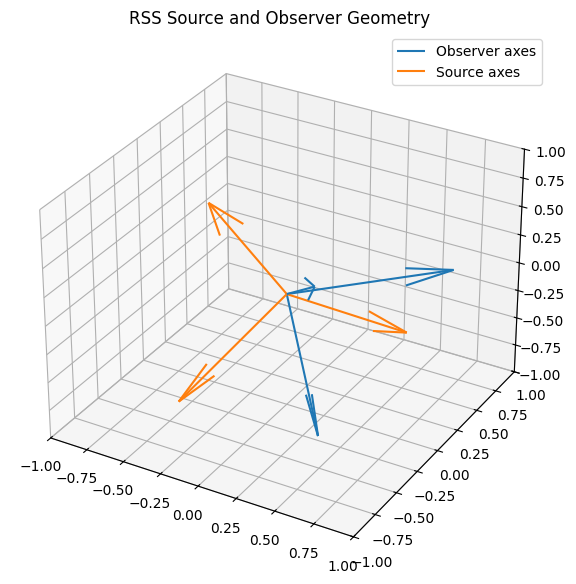

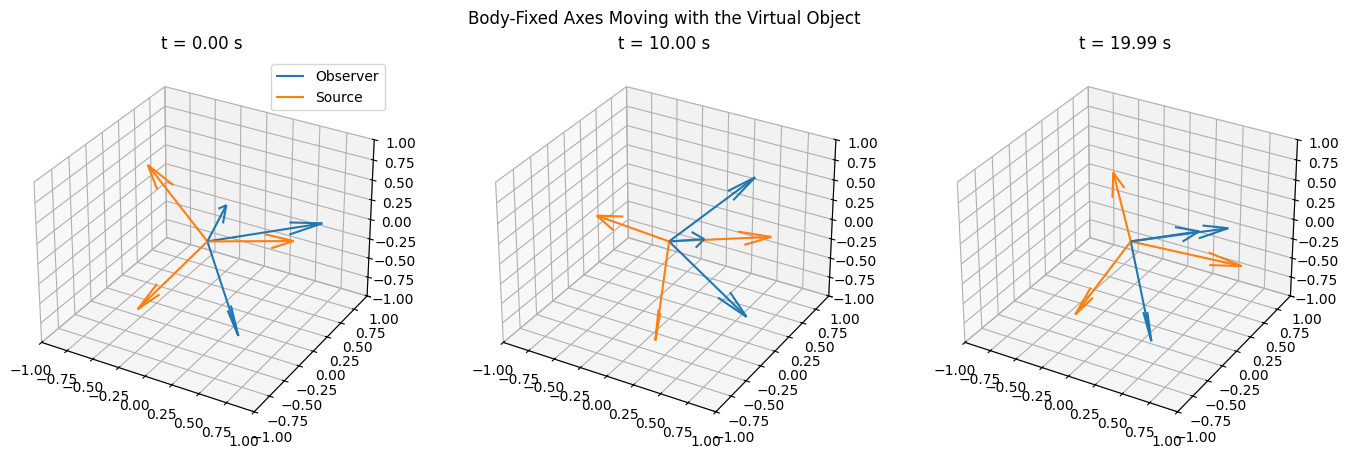

In [16]:
display_one_figure(plot_rotation_geometry(scenario))
display_one_figure(plot_moving_rotation_geometry(scenario))

## 3. Fit RSS and inspect the optimized SO(3) matrix

In [5]:
single_corr_run, single_specialized_run = run_paired_rss_for_scenario(
    scenario, single_rss_config, single_specialized_loss_config,
)
corr_validation = single_corr_run.validation
validation = single_specialized_run.validation
rss_result = validation.rss_result
print('Optimizer:', rss_result.optimizer_name)
print('Primary separation loss:', rss_result.config.loss_type)
print('MI estimator:', rss_result.config.mi_estimator)
print('MI unit: nats')
print('GCMI rank method:', rss_result.config.gcmi_rank_method)
print('B-spline bins/order:', rss_result.config.bspline_bins, rss_result.config.bspline_order)
print('KSG k:', rss_result.config.ksg_k)
print('KSG standardization:', rss_result.config.ksg_standardize)
print('KSG maximum samples:', rss_result.config.ksg_max_samples)
print('KSG subsampling mode/seed:', rss_result.config.ksg_subsample_mode, rss_result.config.ksg_subsample_seed)
effective_ksg_samples = rss_result.source_angles.shape[1] if rss_result.config.ksg_max_samples is None else min(rss_result.source_angles.shape[1], rss_result.config.ksg_max_samples)
print('KSG effective sample count:', effective_ksg_samples)
print('Applied sample interval (s):', rss_result.sample_interval_seconds)
print('Initial recovery/weight matrix:')
print(rss_result.config.resolved_initial_matrix)
print('Learning-rate schedule: exponential')
print('Configured learning-rate start:', rss_result.config.learning_rate)
print('Configured learning-rate end:', rss_result.config.learning_rate_end)
print('First applied learning rate:', rss_result.applied_learning_rates[0] if rss_result.applied_learning_rates else None)
print('Terminal applied learning rate:', rss_result.applied_learning_rates[-1] if rss_result.applied_learning_rates else None)
print('Optimized six weights:', rss_result.optimized_weights)
print('Optimized SO(3) recovery matrix:')
print(rss_result.recovery_matrix)
print('Recovered direction-cosine Gram matrix A A^T:')
print(rss_result.recovery_matrix @ rss_result.recovery_matrix.T)
print('Symmetry error:', rss_result.matrix_diagnostics.symmetry_error)
print('Orthogonality error:', rss_result.matrix_diagnostics.orthogonality_error)
print('Determinant:', rss_result.matrix_diagnostics.determinant)
print('Singular values:', rss_result.matrix_diagnostics.singular_values)
print('Condition number:', rss_result.matrix_diagnostics.condition_number)
print('Warnings:', rss_result.matrix_diagnostics.warnings)
print('Stop reason:', rss_result.stop_reason, '| best epoch:', rss_result.best_epoch)
print('Raw initial-loss normalization reference:', rss_result.loss_normalization_reference)
print('Normalized initial loss:', rss_result.normalized_initial_loss)
print('Normalized best loss:', rss_result.normalized_best_loss)
print('Normalized terminal loss:', rss_result.normalized_terminal_loss)
best_history = rss_result.loss_history[rss_result.best_epoch]
print('Raw full-quaternion reconstruction loss:', best_history['reconstruction_loss'])
print('Normalized weighted reconstruction contribution:', best_history['normalized_reconstruction_loss'])
print('Mean relative rotation error (deg):', np.degrees(rss_result.reconstruction_mean_error_rad))
print('Maximum relative rotation error (deg):', np.degrees(rss_result.reconstruction_max_error_rad))
quaternion_comparison = pd.concat(
    {
        'q_R observed': pd.DataFrame(rss_result.observer_quaternions, columns=['w', 'x', 'y', 'z']),
        'q_S source-composed': pd.DataFrame(rss_result.composed_source_quaternions, columns=['w', 'x', 'y', 'z']),
        'q_delta closest to I': pd.DataFrame(rss_result.relative_reconstruction_quaternions, columns=['w', 'x', 'y', 'z']),
    },
    axis=1,
)
display(quaternion_comparison.head(10))
print('Ground-truth source cross-correlation matrix:')
print(validation.original_source_cross_correlation_matrix)
print('Matched separated-source cross-correlation matrix:')
print(validation.separated_source_cross_correlation_matrix)
print('Ground-truth maximum absolute cross-correlation:', validation.metrics['original_source_max_abs_cross_correlation'])
print('Separated maximum absolute cross-correlation:', validation.metrics['separated_source_max_abs_cross_correlation'])
print('Ground-truth threshold passed:', validation.metrics['original_source_max_abs_cross_correlation'] < scenario.config.source_cross_correlation_limit)
display(pd.DataFrame([validation.metrics]).T.rename(columns={0: 'value'}))
display_one_figure(plot_loss_history(rss_result.loss_history))
print('Zero-lag RSS mean |correlation|:', corr_validation.metrics['mean_abs_source_correlation'])
print('Specialized RSS mean |correlation|:', validation.metrics['mean_abs_source_correlation'])
print('Zero-lag RSS aligned frame error (deg):', single_corr_run.validation.metrics['so3_frame_error_aligned_deg'])
print('Specialized RSS aligned frame error (deg):', single_specialized_run.validation.metrics['so3_frame_error_aligned_deg'])
display_one_figure(plot_structural_diagnostic(single_specialized_run, 'Single-case specialized-loss diagnostic'))


KeyboardInterrupt: 

## 4. Source recovery and geometry evaluation

In [5]:
resolved_single_config = SpecializedRSSConfigView(
    single_rss_config, FAMILY_LOSS_MODES[single_signal_type], single_specialized_loss_config,
)
if validation.scenario is not scenario or validation.rss_result.config != resolved_single_config:
    raise RuntimeError(
        'The scenario or RSS controls changed after fitting. Re-run section 3 before plotting section 4.'
    )
plot_builders = (
    ('Observed and true source signals', plot_observed_signals),
    ('Matched source recovery', plot_source_comparison),
    ('Observed versus source-composed observer angles', plot_observer_reconstruction),
    ('Source-axis comparison', plot_source_axis_comparison),
)
for plot_label, builder in plot_builders:
    print(plot_label)
    display_one_figure(builder(validation))
print('Matched permutation:', validation.match.permutation)
print('Matched signs:', validation.match.signs)
print('Per-source absolute correlations:', validation.match.correlations)

NameError: name 'validation' is not defined

## 5. Batch-suite configuration

The batch MI backend is independently selectable below. GCMI and KSG require `optimizer='pso'`; B-spline and histogram MI support Adam, SGD, and PSO. Set `ksg_max_samples` to a positive integer to test deterministic KSG subsampling, or leave it as `None` for full KSG. No automatic timing is performed.

In [6]:
BATCH_ARTIFACT_ROOT = REPO_ROOT / 'notebooks' / 'artifacts' / 'rss_validation_specialized_losses'
RUN_STANDARD_FAMILY_SUITE = True
RUN_STRESS_SUITE = True
RUN_FORMAL_EXPERIMENT_SUITE = True
batch_study_config = BatchStudyConfig()
formal_cases_per_family = 50
formal_base_seed = 20000
formal_study_config = replace(
    batch_study_config, standard_cases_per_family=formal_cases_per_family,
)
batch_sim_config = SimulationConfig(
    seed=0, T=2000,
    source_cross_correlation_limit=source_cross_correlation_limit,
)
batch_loss_type = 'lagged_cross_correlation'  # lagged_cross_correlation, mutual_information, or action
# batch_lags = (0,1,2,3,5,7,11,13,17,19,23,29,31,37,41,43,47)
batch_lags = (0,)
batch_mi_estimator = 'histogram'  # gcmi, bspline, ksg, or histogram
batch_gcmi_rank_method = 'average'
batch_bspline_bins = 6
batch_bspline_order = 3
batch_ksg_k = 4
batch_ksg_standardize = True
batch_ksg_max_samples = 1000  # None uses full KSG; set 500, 1000, etc. for a fixed subset.
batch_ksg_subsample_mode = 'fixed_random'
batch_ksg_subsample_seed = 0
batch_mi_bins = 16
batch_mi_bandwidth = 0.2
batch_action_inertias = (1.0, 1.0, 1.0)
batch_action_stiffnesses = (1.0, 1.0, 1.0)
batch_rss_config = RSSConfig(
    loss_type=batch_loss_type,
    separation_weight=1.0,
    lags=batch_lags,
    mi_estimator=batch_mi_estimator,
    gcmi_rank_method=batch_gcmi_rank_method,
    bspline_bins=batch_bspline_bins,
    bspline_order=batch_bspline_order,
    ksg_k=batch_ksg_k,
    ksg_standardize=batch_ksg_standardize,
    ksg_max_samples=batch_ksg_max_samples,
    ksg_subsample_mode=batch_ksg_subsample_mode,
    ksg_subsample_seed=batch_ksg_subsample_seed,
    mi_bins=batch_mi_bins,
    mi_bandwidth=batch_mi_bandwidth,
    action_inertias=batch_action_inertias,
    action_stiffnesses=batch_action_stiffnesses,
    epochs=3 if QUICK_MODE else 2000,
    optimizer='pso',  # adam, sgd, or pso
    learning_rate=1e-1,
    learning_rate_end=1e-3,
    sgd_momentum=0.9,
    pso_swarm_size=200, pso_inertia=0.9,
    pso_cognitive=1.0, pso_social=1.5,
    matrix_parameterization='so3',
    # This synthetic body-fixed gyro validation generates integrated body
    # rotation channels, so we explicitly use the integrated_body_rotation path.
    observer_signal_model='integrated_body_rotation',
    initial_weight_matrix=manual_initial_weight_matrix,
    pso_seed=0,
    orthogonality_weight=0.0,
    reconstruction_weight=0.0,
    convergence_tol=0.0,  # RSS always runs the complete epoch budget.
    eps=1e-24,
    quaternion_eps=1e-24,
)
print('Batch MI estimator:', batch_rss_config.mi_estimator)
print('Batch MI unit: nats')
print('Batch GCMI rank method:', batch_rss_config.gcmi_rank_method)
print('Batch B-spline bins/order:', batch_rss_config.bspline_bins, batch_rss_config.bspline_order)
print('Batch KSG k:', batch_rss_config.ksg_k)
print('Batch KSG standardization:', batch_rss_config.ksg_standardize)
print('Batch KSG maximum samples:', batch_rss_config.ksg_max_samples)
print('Batch KSG subsampling mode/seed:', batch_rss_config.ksg_subsample_mode, batch_rss_config.ksg_subsample_seed)
batch_effective_ksg_samples = batch_sim_config.T if batch_rss_config.ksg_max_samples is None else min(batch_sim_config.T, batch_rss_config.ksg_max_samples)
print('Batch KSG effective sample count:', batch_effective_ksg_samples)
print('Batch initial recovery/weight matrix:')

print(batch_rss_config.resolved_initial_matrix)

RUN_REGRESSION_CHECK = True
RUN_LOSS_LANDSCAPES = True
RUN_HYPERPARAMETER_SENSITIVITY = True
RUN_CROSS_LOSS_DIAGNOSTIC = False
LANDSCAPE_RANDOM_ROTATIONS = 64 if QUICK_MODE else 2000
LANDSCAPE_RANDOM_SEED = 41000
DEFAULT_SPECIALIZED_LOSS_CONFIG = SpecializedLossConfig()
print('Family-specific loss mapping:', FAMILY_LOSS_MODES)
print('Specialized loss defaults:', asdict(DEFAULT_SPECIALIZED_LOSS_CONFIG))


Batch MI estimator: histogram
Batch MI unit: nats
Batch GCMI rank method: average
Batch B-spline bins/order: 6 3
Batch KSG k: 4
Batch KSG standardization: True
Batch KSG maximum samples: 1000
Batch KSG subsampling mode/seed: fixed_random 0
Batch KSG effective sample count: 1000
Batch initial recovery/weight matrix:
[[-0.4779 -0.5421 -0.6911]
 [-0.5984  0.777  -0.1956]
 [ 0.643   0.3201 -0.6957]]
Family-specific loss mapping: {'harmonic': 'harmonic_spectral_overlap', 'filtered_noise': 'filtered_multilag_cross_correlation', 'chirp_modulated': 'chirp_time_frequency_overlap', 'piecewise_transient': 'piecewise_sparse_innovation'}
Specialized loss defaults: {'bad_loss': 1000000.0, 'variance_floor': 1e-12, 'numerical_eps': 1e-12, 'unwrap_for_loss': True, 'analysis_band_hz': (0.0, 5.0), 'harmonic_nperseg': 256, 'harmonic_overlap_fraction': 0.5, 'harmonic_gamma': 1.0, 'filtered_max_lag': 100, 'chirp_nperseg': 128, 'chirp_noverlap': 96, 'chirp_nfft': 256, 'chirp_energy_weighted': False, 'piecewi

## 5A. Zero-lag regression check

One deterministic case from every family is fitted through both the existing RSS solver
and the notebook-local PSO path using the same zero-lag objective. Recovery matrices,
global-best histories, and final losses must agree before specialized results are interpreted.

In [6]:
regression_rows = []
representative_specs = [
    next(spec for spec in create_standard_case_specs(batch_study_config) if spec.family == family)
    for family in batch_study_config.standard_families
]
representative_scenarios = {}
if RUN_REGRESSION_CHECK:
    for spec in representative_specs:
        case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        representative_scenarios[spec.family] = case
        validate_zero_mean_sources(case)
        interval = float(np.median(np.diff(case.time_seconds)))
        reference = run_validation_for_scenario(case, batch_rss_config)
        local = fit_specialized_rss(
            case.observations,
            batch_rss_config,
            {'mode': LOSS_CORR_ZERO_LAG, 'config': DEFAULT_SPECIALIZED_LOSS_CONFIG},
            interval,
        ).rss_result
        reference_history = np.asarray([row['total_loss'] for row in reference.rss_result.loss_history])
        local_history = np.asarray([row['total_loss'] for row in local.loss_history])
        matrix_error = float(np.max(np.abs(reference.rss_result.recovery_matrix - local.recovery_matrix)))
        history_error = float(np.max(np.abs(reference_history - local_history)))
        assert np.allclose(reference.rss_result.recovery_matrix, local.recovery_matrix, atol=1e-10, rtol=1e-10)
        assert np.allclose(reference_history, local_history, atol=1e-10, rtol=1e-10)
        regression_rows.append({
            'family': spec.family, 'case_id': spec.case_id,
            'maximum_matrix_error': matrix_error,
            'maximum_loss_history_error': history_error,
            'reference_best_loss': reference.rss_result.best_loss,
            'local_best_loss': local.best_loss,
        })
regression_frame = pd.DataFrame(regression_rows)
display(regression_frame)

KeyboardInterrupt: 

## 5B. Source-family loss landscapes

The specialized loss at the known physical frame is compared with seeded random proper
rotations. Raw Eq. 69 distance is reported alongside the signed-permutation-aligned distance
needed for objectives that are invariant to source order and sign.

In [7]:
def reconstruct_for_matrices(scenario, matrices):
    observer_quaternions = integrated_body_angles_to_quaternions(
        scenario.observations, eps=float(batch_rss_config.quaternion_eps),
    )
    scalar = torch.as_tensor(observer_quaternions[:, 0], dtype=torch.float64)
    vector = torch.as_tensor(observer_quaternions[:, 1:].T, dtype=torch.float64)
    matrix_tensor = torch.as_tensor(np.asarray(matrices), dtype=torch.float64)
    source_vectors = torch.einsum('pij,jt->pit', matrix_tensor, vector)
    return _decode_scalar_and_vector_batch(
        scalar, source_vectors, eps=float(batch_rss_config.quaternion_eps),
    )


def evaluate_loss_landscape(scenario, loss_config, random_count, seed):
    rng = np.random.default_rng(int(seed))
    random_matrices = np.stack([random_orthonormal_axes(3, rng) for _ in range(int(random_count))])
    mode = FAMILY_LOSS_MODES[scenario.family]
    fs = 1.0 / float(np.median(np.diff(scenario.time_seconds)))
    losses = []
    for start in range(0, len(random_matrices), 128):
        sources = reconstruct_for_matrices(scenario, random_matrices[start:start + 128])
        losses.append(compute_specialized_loss(
            sources, fs, mode, loss_config,
        ).detach().cpu().numpy())
    losses = np.concatenate(losses)
    true_sources = reconstruct_for_matrices(scenario, scenario.mixing_matrix[None, ...])[0]
    true_loss, true_diagnostics = compute_specialized_loss(
        true_sources, fs, mode, loss_config, return_diagnostics=True,
    )
    true_loss = float(true_loss.detach().cpu())
    true_diagnostics = _to_numpy_diagnostics(true_diagnostics)
    raw_errors = np.asarray([
        so3_geodesic_error(matrix, scenario.mixing_matrix) for matrix in random_matrices
    ])
    aligned_errors = np.asarray([
        symmetry_aligned_so3_error(matrix, scenario.mixing_matrix) for matrix in random_matrices
    ])
    rank = 1 + int(np.count_nonzero(losses < true_loss))
    percentile = 100.0 * float(np.count_nonzero(losses <= true_loss)) / float(len(losses))
    return {
        'family': scenario.family, 'case_id': scenario.case_id,
        'loss_mode': mode, 'true_loss': true_loss, 'true_rank': rank,
        'true_percentile': percentile, 'random_losses': losses,
        'raw_frame_errors_rad': raw_errors,
        'aligned_frame_errors_rad': aligned_errors,
        'true_diagnostics': true_diagnostics,
    }


loss_landscapes = {}
if RUN_LOSS_LANDSCAPES:
    landscape_root = BATCH_ARTIFACT_ROOT / 'loss_landscapes'
    landscape_root.mkdir(parents=True, exist_ok=True)
    for family_index, family in enumerate(batch_study_config.standard_families):
        case = representative_scenarios.get(family)
        if case is None:
            spec = next(spec for spec in representative_specs if spec.family == family)
            case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
            representative_scenarios[family] = case
            validate_zero_mean_sources(case)
        landscape = evaluate_loss_landscape(
            case, DEFAULT_SPECIALIZED_LOSS_CONFIG, LANDSCAPE_RANDOM_ROTATIONS,
            LANDSCAPE_RANDOM_SEED + family_index,
        )
        loss_landscapes[family] = landscape
        frame = pd.DataFrame({
            'loss': landscape['random_losses'],
            'raw_frame_error_rad': landscape['raw_frame_errors_rad'],
            'aligned_frame_error_rad': landscape['aligned_frame_errors_rad'],
        })
        frame.to_csv(landscape_root / f'{family}_random_candidates.csv', index=False)
        figure, axes = plt.subplots(1, 3, figsize=(17, 4.5))
        axes[0].scatter(np.degrees(frame['raw_frame_error_rad']), frame['loss'], s=9, alpha=0.45)
        axes[0].set_xlabel('Raw SO(3) error (deg)')
        axes[0].set_ylabel('Specialized loss')
        axes[1].scatter(np.degrees(frame['aligned_frame_error_rad']), frame['loss'], s=9, alpha=0.45)
        axes[1].set_xlabel('Aligned SO(3) error (deg)')
        axes[1].set_ylabel('Specialized loss')
        axes[2].hist(frame['loss'], bins=40)
        axes[2].axvline(landscape['true_loss'], color='red', label='True frame')
        axes[2].set_xlabel('Specialized loss')
        axes[2].legend()
        figure.suptitle(
            f"{family}: true rank {landscape['true_rank']}/{len(frame) + 1}, "
            f"percentile {landscape['true_percentile']:.2f}%"
        )
        figure.tight_layout()
        figure.savefig(landscape_root / f'{family}_landscape.png', dpi=150, bbox_inches='tight')
        display_one_figure(figure)
    landscape_summary = pd.DataFrame([
        {key: value for key, value in item.items() if key in (
            'family', 'case_id', 'loss_mode', 'true_loss', 'true_rank', 'true_percentile'
        )}
        for item in loss_landscapes.values()
    ])
    landscape_summary.to_csv(landscape_root / 'landscape_summary.csv', index=False)
    display(landscape_summary)

NameError: name 'representative_scenarios' is not defined

## 6. Standard 20-case family suite

Paired standard case 1/20: harmonic_01
Paired standard case 2/20: harmonic_02
Paired standard case 3/20: harmonic_03
Paired standard case 4/20: harmonic_04
Paired standard case 5/20: harmonic_05
Paired standard case 6/20: filtered_noise_01
Paired standard case 7/20: filtered_noise_02
Paired standard case 8/20: filtered_noise_03
Paired standard case 9/20: filtered_noise_04
Paired standard case 10/20: filtered_noise_05
Paired standard case 11/20: chirp_modulated_01
Paired standard case 12/20: chirp_modulated_02
Paired standard case 13/20: chirp_modulated_03
Paired standard case 14/20: chirp_modulated_04
Paired standard case 15/20: chirp_modulated_05
Paired standard case 16/20: piecewise_transient_01
Paired standard case 17/20: piecewise_transient_02
Paired standard case 18/20: piecewise_transient_03
Paired standard case 19/20: piecewise_transient_04
Paired standard case 20/20: piecewise_transient_05


,family,source_1_realized_amplitude_rad,source_1_realized_frequency_hz,source_2_realized_amplitude_rad,source_2_realized_frequency_hz,source_3_realized_amplitude_rad,source_3_realized_frequency_hz,mean_requested_amplitude_rad,mean_requested_frequency_hz,rss_bspline_bins,...,runtime_seconds,so3_frame_error_rad,so3_frame_error_deg,so3_frame_error_aligned_rad,so3_frame_error_aligned_deg,reconstruction_success_threshold_deg,specialized_loss_value,specialized_pair_component_12,specialized_pair_component_13,specialized_pair_component_23
0,chirp_modulated,0.744513,1.750661,0.765285,1.963955,0.827863,1.642196,NaN,NaN,6.0,...,21.570956,2.246423,128.710559,0.489305,28.035094,5.0,0.705177,0.631644,0.653389,0.830498
1,filtered_noise,0.773504,0.244378,0.715058,0.470238,0.852417,0.565476,NaN,NaN,6.0,...,14.121084,2.239035,128.287235,0.380475,21.799616,5.0,0.006771,0.006280,0.008010,0.006022
2,harmonic,0.727762,0.945767,0.698595,0.489749,0.755849,0.589947,NaN,NaN,6.0,...,10.481295,1.528426,87.572368,0.282591,16.191244,5.0,0.800066,0.862376,0.724795,0.813027
3,piecewise_transient,0.804202,0.223545,0.830578,0.215939,0.770230,0.309193,NaN,NaN,6.0,...,9.167164,1.612540,92.391730,0.334649,19.173980,5.0,0.203551,0.212407,0.482124,0.159884


,family,case_id,delta_abs_correlation,delta_rmse_rad,delta_so3_frame_error_aligned_rad
0,harmonic,harmonic_01,0.075583,-0.039240,-0.336386
1,harmonic,harmonic_02,-0.105496,0.130148,0.492904
2,harmonic,harmonic_03,0.240367,-0.414802,-0.797353
3,harmonic,harmonic_04,0.095605,-0.139514,-0.444867
4,harmonic,harmonic_05,-0.045890,0.043885,0.195569
5,filtered_noise,filtered_noise_01,-0.004348,0.004966,0.069586
6,filtered_noise,filtered_noise_02,0.041803,-0.020036,-0.214775
7,filtered_noise,filtered_noise_03,-0.066817,0.042419,0.230702
8,filtered_noise,filtered_noise_04,-0.023935,0.028550,0.061027
9,filtered_noise,filtered_noise_05,-0.080704,0.055414,0.266641


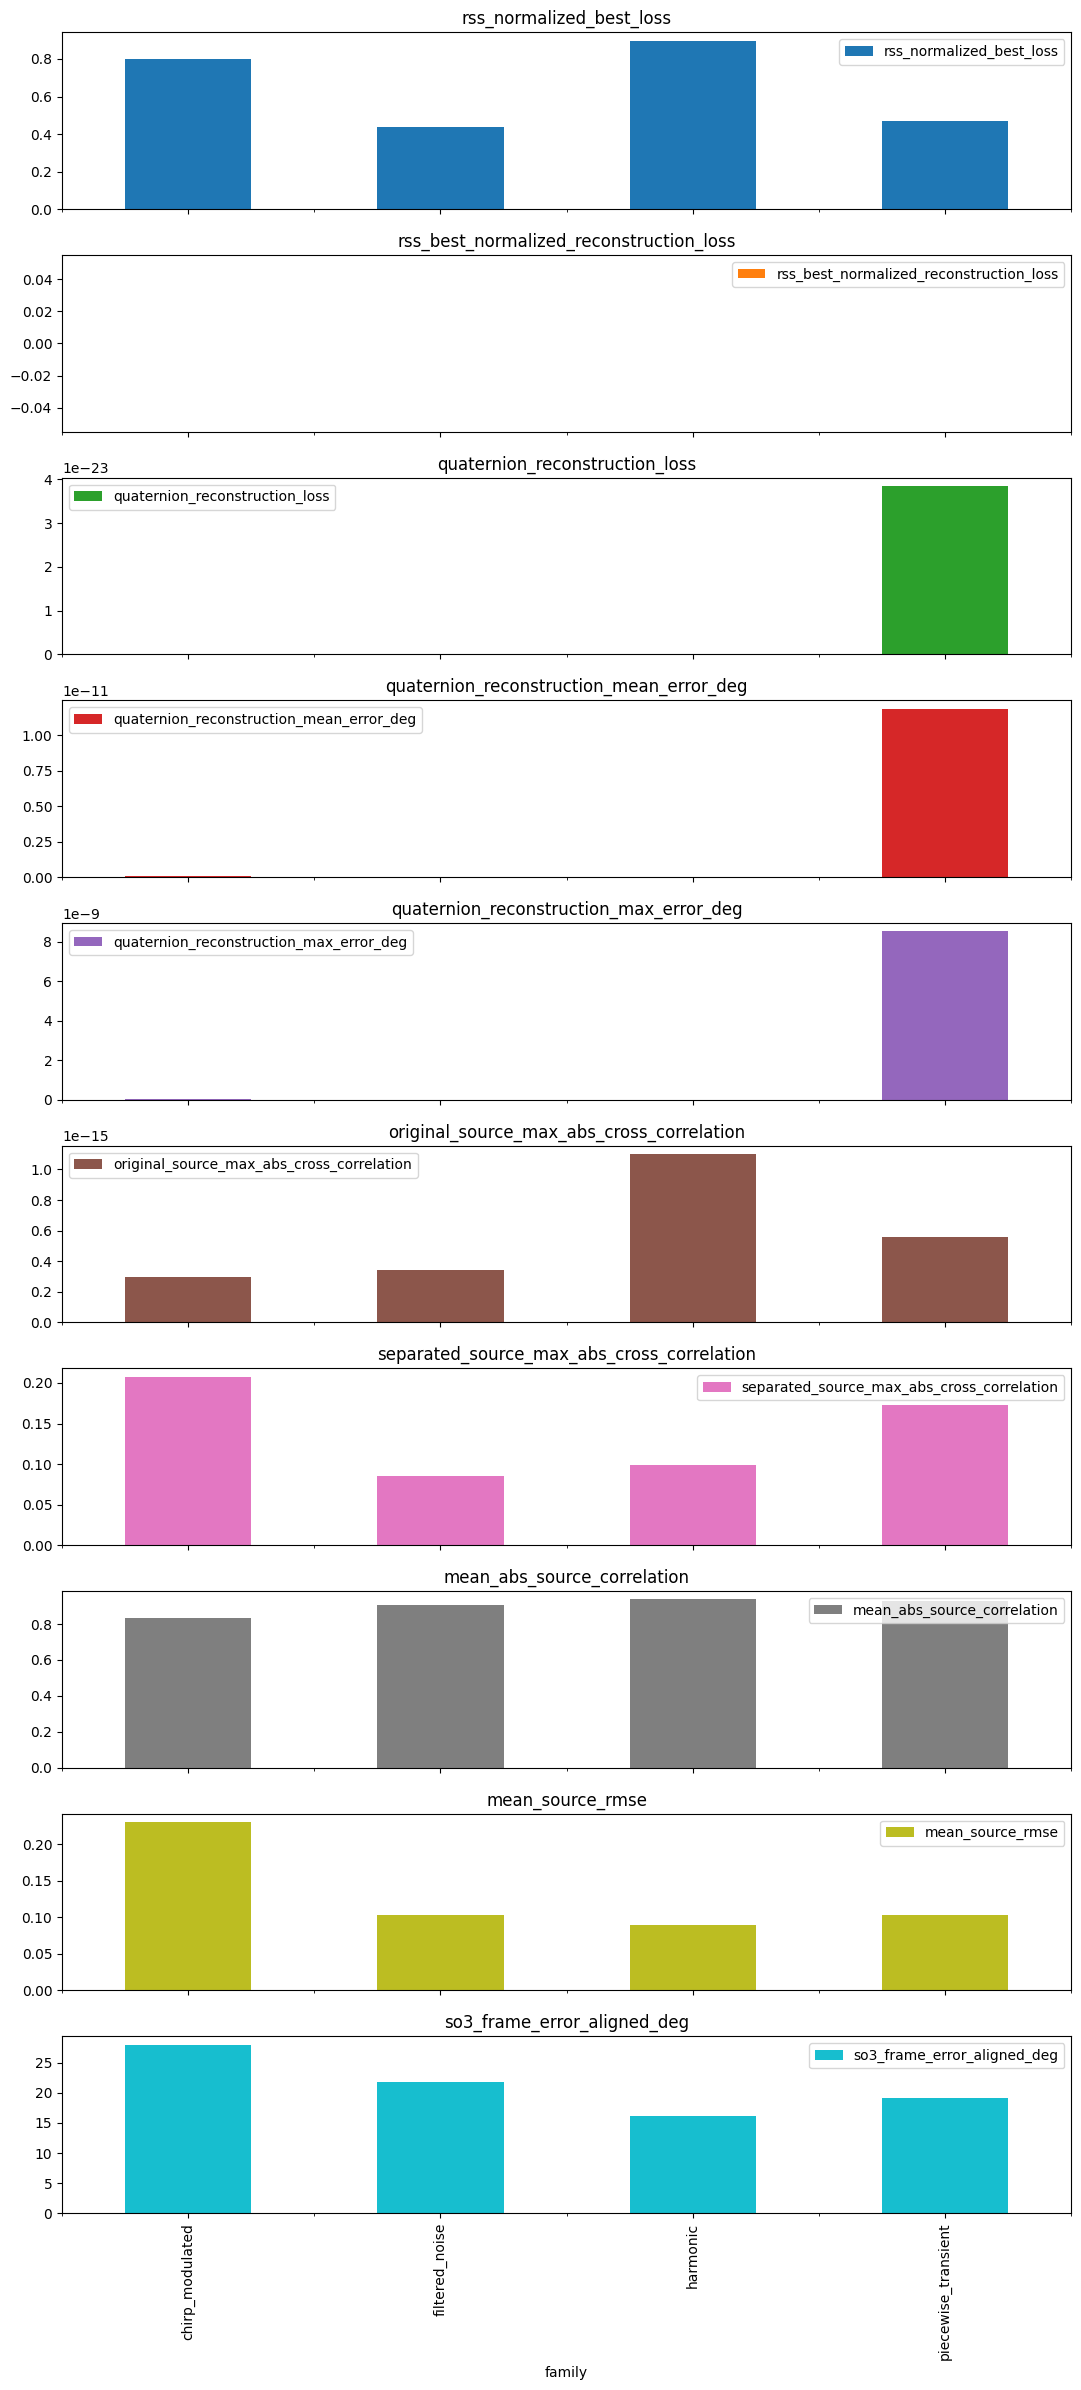

In [22]:
standard_results = []
standard_corr_results = []
standard_specialized_runs = []
standard_corr_runs = []
standard_scenarios = {}
if RUN_STANDARD_FAMILY_SUITE:
    standard_specs = create_standard_case_specs(batch_study_config)
    if QUICK_MODE:
        standard_specs = [
            next(spec for spec in standard_specs if spec.family == family)
            for family in batch_study_config.standard_families
        ]
    for index, spec in enumerate(standard_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        standard_scenarios[spec.case_id] = case
        validate_zero_mean_sources(case)
        corr_run, specialized_run = run_paired_rss_for_scenario(
            case, batch_rss_config, DEFAULT_SPECIALIZED_LOSS_CONFIG,
        )
        export_experiment_run(
            corr_run,
            BATCH_ARTIFACT_ROOT / corr_run.method_key / 'standard_families' / 'cases' / spec.family / spec.case_id,
        )
        export_experiment_run(
            specialized_run,
            BATCH_ARTIFACT_ROOT / specialized_run.method_key / 'standard_families' / 'cases' / spec.family / spec.case_id,
        )
        standard_corr_runs.append(corr_run)
        standard_specialized_runs.append(specialized_run)
        standard_corr_results.append(corr_run.validation)
        standard_results.append(specialized_run.validation)
        print(f'Paired standard case {index}/{len(standard_specs)}: {spec.case_id}')
    standard_metrics = build_metrics_frame(standard_results)
    standard_corr_metrics = build_metrics_frame(standard_corr_results)
    standard_summary = summarize_standard_suite(standard_metrics)
    standard_paired_frame = build_paired_rss_frame(standard_corr_runs, standard_specialized_runs)
    summary_root = BATCH_ARTIFACT_ROOT / 'standard_families' / 'summary'
    summary_root.mkdir(parents=True, exist_ok=True)
    standard_metrics.to_csv(summary_root / 'specialized_per_case_metrics.csv', index=False)
    standard_corr_metrics.to_csv(summary_root / 'corr_per_case_metrics.csv', index=False)
    standard_paired_frame.to_csv(summary_root / 'paired_rss_differences.csv', index=False)
    standard_summary.to_csv(summary_root / 'family_average_metrics.csv', index=False)
    display(standard_summary)
    display(standard_paired_frame[[
        'family', 'case_id', 'delta_abs_correlation', 'delta_rmse_rad',
        'delta_so3_frame_error_aligned_rad',
    ]])
    summary_axes = standard_summary.plot.bar(
        x='family',
        y=[
            'rss_normalized_best_loss', 'rss_best_normalized_reconstruction_loss',
            'quaternion_reconstruction_loss', 'quaternion_reconstruction_mean_error_deg',
            'quaternion_reconstruction_max_error_deg', 'original_source_max_abs_cross_correlation',
            'separated_source_max_abs_cross_correlation', 'mean_abs_source_correlation',
            'mean_source_rmse', 'so3_frame_error_aligned_deg',
        ],
        subplots=True, figsize=(11, 24),
    )
    summary_figure = np.asarray(summary_axes).reshape(-1)[0].figure
    summary_figure.tight_layout()
    display_one_figure(summary_figure)

## 7. Eight-case large-rotation stress suite

Paired stress case 1/8: harmonic_stress_01
Paired stress case 2/8: harmonic_stress_02
Paired stress case 3/8: harmonic_stress_03
Paired stress case 4/8: harmonic_stress_04
Paired stress case 5/8: harmonic_stress_05
Paired stress case 6/8: harmonic_stress_06
Paired stress case 7/8: harmonic_stress_07
Paired stress case 8/8: harmonic_stress_08


,family,case_id,seed,frame_count,amplitude_tier,stress_peak_angle_rad,composition,replicate_index,source_roles,simulation_observation_model,...,so3_frame_error_rad,so3_frame_error_deg,so3_frame_error_aligned_rad,so3_frame_error_aligned_deg,reconstruction_success,reconstruction_success_threshold_deg,specialized_loss_value,specialized_pair_component_12,specialized_pair_component_13,specialized_pair_component_23
0,harmonic,harmonic_stress_01,7300,720,high,0.55,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.813315,161.191048,0.335906,19.245973,False,5.0,0.718381,0.851218,0.725239,0.578685
1,harmonic,harmonic_stress_02,7331,840,high,0.85,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,3.136484,179.707310,0.056539,3.239444,True,5.0,0.672602,0.400644,0.801773,0.815390
2,harmonic,harmonic_stress_03,7362,960,high,1.15,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.997809,171.761825,0.690008,39.534534,False,5.0,0.818574,0.791338,0.709111,0.955274
3,harmonic,harmonic_stress_04,7393,1080,high,1.45,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.928479,167.789501,0.213657,12.241630,False,5.0,0.739512,0.628227,0.936318,0.653992
4,harmonic,harmonic_stress_05,7424,720,high,1.75,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,1.898352,108.767555,0.681020,39.019544,False,5.0,0.633095,0.481523,0.994940,0.422823
5,harmonic,harmonic_stress_06,7455,840,high,2.05,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.288692,131.132409,0.231607,13.270125,False,5.0,0.607951,0.438089,0.996993,0.388770
6,harmonic,harmonic_stress_07,7486,960,high,2.35,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,2.782855,159.445861,0.735466,42.139079,False,5.0,0.712977,0.571098,0.998639,0.569193
7,harmonic,harmonic_stress_08,7517,1080,high,2.65,triple_rotation,None,dense|dense|dense,body_fixed_gyro,...,3.036345,173.969770,0.865759,49.604314,False,5.0,0.621435,0.431944,0.999465,0.432896


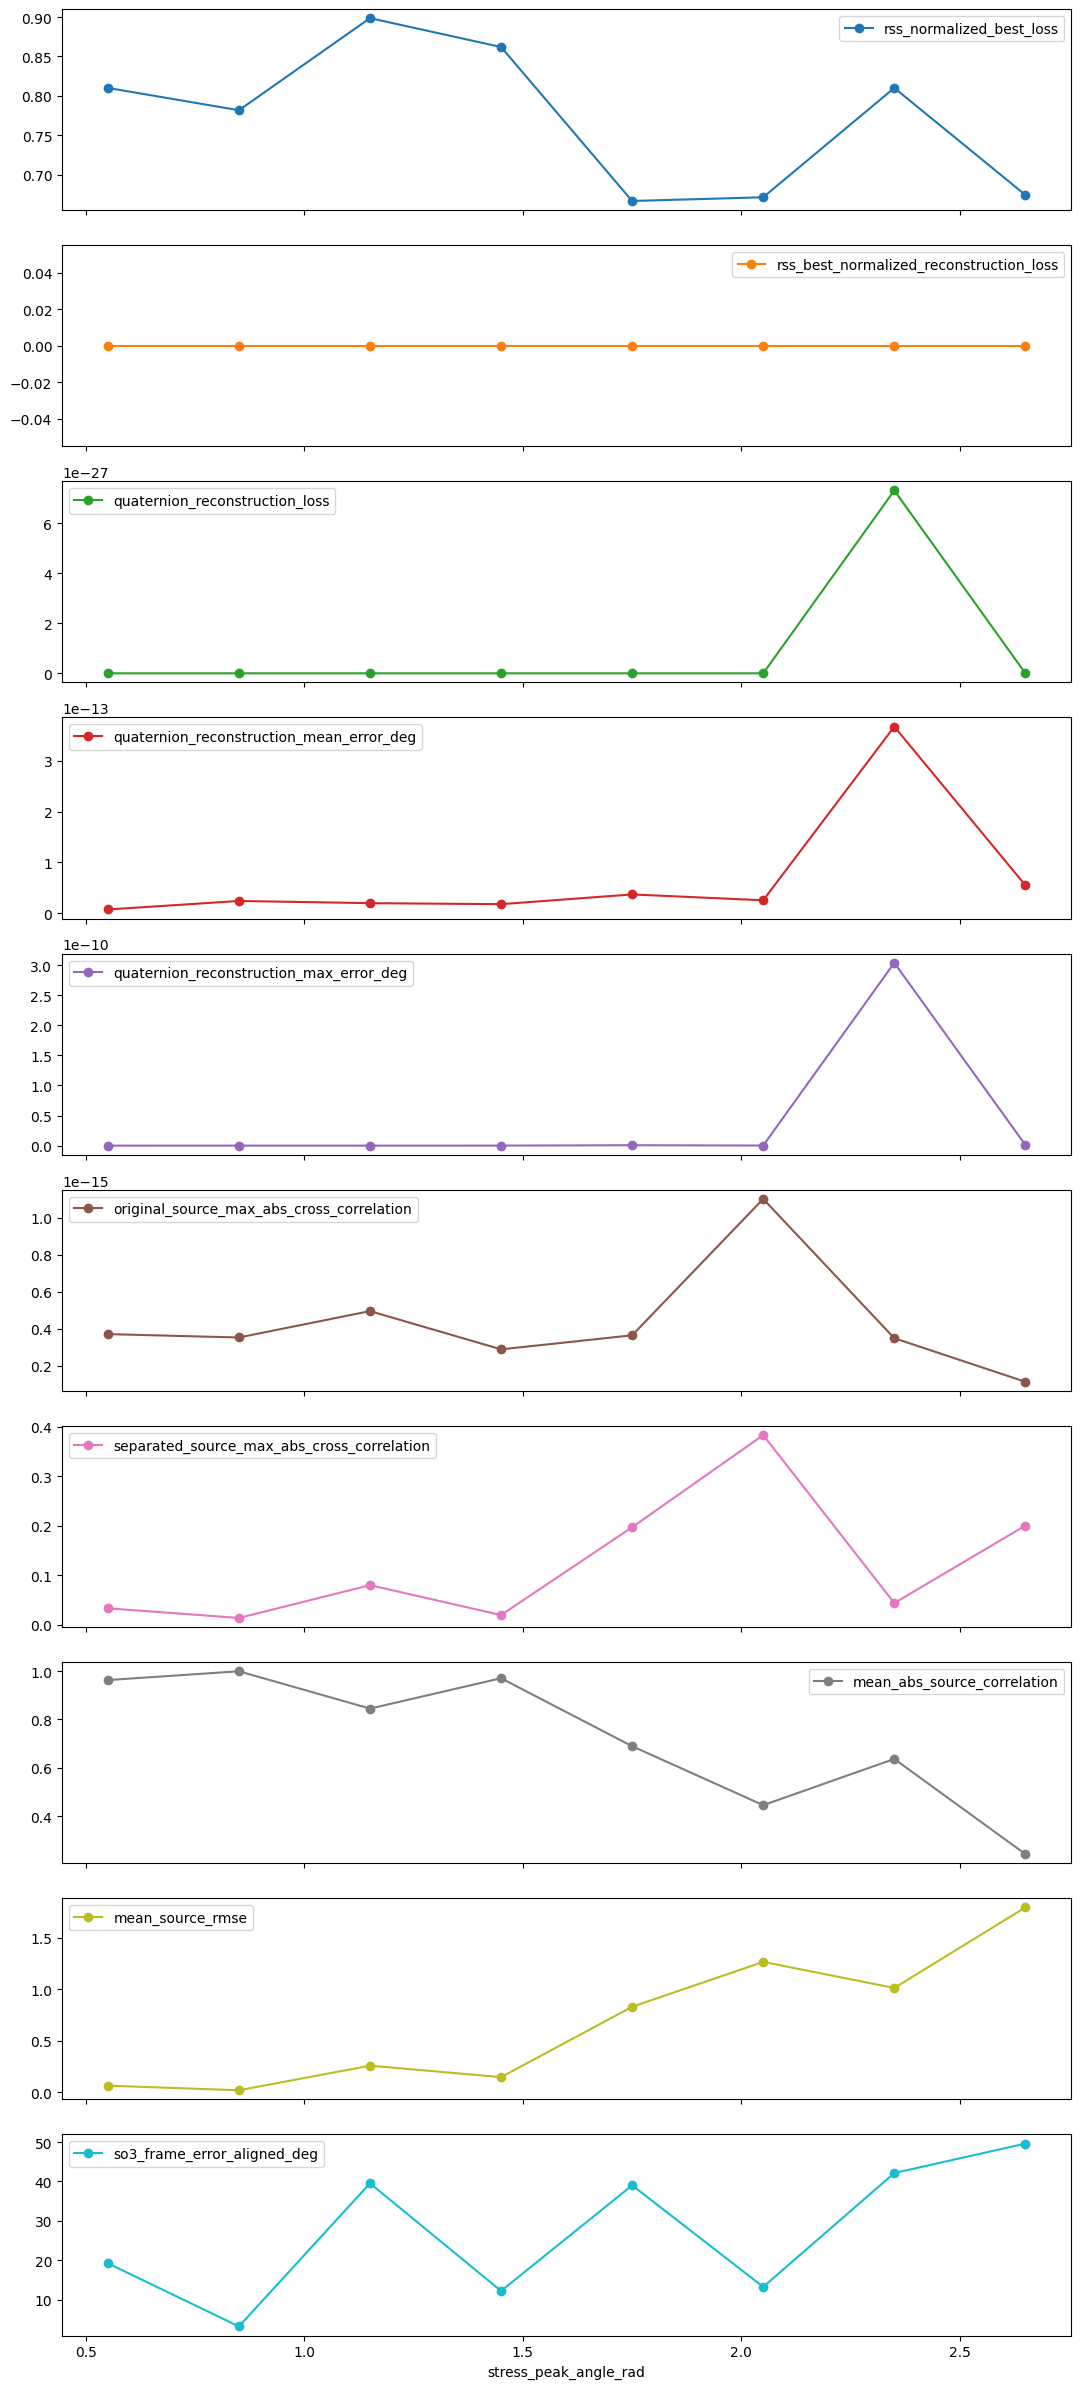

In [23]:
stress_results = []
stress_corr_results = []
stress_specialized_runs = []
stress_corr_runs = []
stress_scenarios = {}
if RUN_STRESS_SUITE:
    stress_specs = create_stress_case_specs(batch_study_config)
    if QUICK_MODE:
        stress_specs = stress_specs[:2]
    for index, spec in enumerate(stress_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        stress_scenarios[spec.case_id] = case
        validate_zero_mean_sources(case)
        corr_run, specialized_run = run_paired_rss_for_scenario(
            case, batch_rss_config, DEFAULT_SPECIALIZED_LOSS_CONFIG,
        )
        export_experiment_run(
            corr_run,
            BATCH_ARTIFACT_ROOT / corr_run.method_key / 'large_rotation_stress' / 'cases' / spec.case_id,
        )
        export_experiment_run(
            specialized_run,
            BATCH_ARTIFACT_ROOT / specialized_run.method_key / 'large_rotation_stress' / 'cases' / spec.case_id,
        )
        stress_corr_runs.append(corr_run)
        stress_specialized_runs.append(specialized_run)
        stress_corr_results.append(corr_run.validation)
        stress_results.append(specialized_run.validation)
        print(f'Paired stress case {index}/{len(stress_specs)}: {spec.case_id}')
    stress_metrics = summarize_stress_suite(build_metrics_frame(stress_results))
    stress_corr_metrics = summarize_stress_suite(build_metrics_frame(stress_corr_results))
    stress_paired_frame = build_paired_rss_frame(stress_corr_runs, stress_specialized_runs)
    stress_root = BATCH_ARTIFACT_ROOT / 'large_rotation_stress' / 'summary'
    stress_root.mkdir(parents=True, exist_ok=True)
    stress_metrics.to_csv(stress_root / 'specialized_stress_metrics.csv', index=False)
    stress_corr_metrics.to_csv(stress_root / 'corr_stress_metrics.csv', index=False)
    stress_paired_frame.to_csv(stress_root / 'paired_rss_differences.csv', index=False)
    display(stress_metrics)
    stress_axes = stress_metrics.plot(
        x='stress_peak_angle_rad',
        y=[
            'rss_normalized_best_loss', 'rss_best_normalized_reconstruction_loss',
            'quaternion_reconstruction_loss', 'quaternion_reconstruction_mean_error_deg',
            'quaternion_reconstruction_max_error_deg', 'original_source_max_abs_cross_correlation',
            'separated_source_max_abs_cross_correlation', 'mean_abs_source_correlation',
            'mean_source_rmse', 'so3_frame_error_aligned_deg',
        ],
        marker='o', subplots=True, figsize=(11, 24),
    )
    stress_figure = np.asarray(stress_axes).reshape(-1)[0].figure
    stress_figure.tight_layout()
    display_one_figure(stress_figure)

## 8. Formal 200-case three-source family experiment

In [ ]:

formal_results = []
formal_corr_results = []
formal_specialized_runs = []
formal_corr_runs = []
formal_scenarios = {}
if RUN_FORMAL_EXPERIMENT_SUITE:
    formal_specs = create_standard_case_specs(
        formal_study_config, base_seed=formal_base_seed, case_id_prefix='formal_',
    )
    standard_seed_set = {spec.seed for spec in create_standard_case_specs(batch_study_config)}
    formal_family_counts = pd.Series([spec.family for spec in formal_specs]).value_counts()
    if len(formal_specs) != 200 or set(formal_family_counts.index) != set(formal_study_config.standard_families):
        raise RuntimeError('The formal suite must contain exactly four standard signal families.')
    if not (formal_family_counts == formal_cases_per_family).all():
        raise RuntimeError('The formal suite must contain exactly 50 cases per signal family.')
    if len({spec.case_id for spec in formal_specs}) != 200 or len({spec.seed for spec in formal_specs}) != 200:
        raise RuntimeError('Formal case IDs and seeds must be unique.')
    if standard_seed_set & {spec.seed for spec in formal_specs}:
        raise RuntimeError('Formal seeds must not overlap the standard 20-case suite.')
    if QUICK_MODE:
        formal_specs = [
            next(spec for spec in formal_specs if spec.family == family)
            for family in formal_study_config.standard_families
        ]
    for index, spec in enumerate(formal_specs, start=1):
        case = generate_family_scenario(spec, batch_sim_config, formal_study_config)
        formal_scenarios[spec.case_id] = case
        validate_zero_mean_sources(case)
        if case.source_roles != ('dense', 'dense', 'dense') or case.active_source_indices != (0, 1, 2):
            raise RuntimeError(f'Formal case {spec.case_id} does not contain three active rotation sources.')
        corr_run, specialized_run = run_paired_rss_for_scenario(
            case, batch_rss_config, DEFAULT_SPECIALIZED_LOSS_CONFIG,
        )
        export_experiment_run(
            corr_run,
            BATCH_ARTIFACT_ROOT / corr_run.method_key / 'formal_experiments' / 'cases' / spec.family / spec.case_id,
            include_plots=False,
        )
        export_experiment_run(
            specialized_run,
            BATCH_ARTIFACT_ROOT / specialized_run.method_key / 'formal_experiments' / 'cases' / spec.family / spec.case_id,
            include_plots=False,
        )
        formal_corr_runs.append(corr_run)
        formal_specialized_runs.append(specialized_run)
        formal_corr_results.append(corr_run.validation)
        formal_results.append(specialized_run.validation)
        print(f'Paired formal case {index}/{len(formal_specs)}: {spec.case_id}')

    formal_paired_frame = build_paired_rss_frame(formal_corr_runs, formal_specialized_runs)
    formal_paired_root = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'summary'
    formal_paired_root.mkdir(parents=True, exist_ok=True)
    formal_paired_frame.to_csv(formal_paired_root / 'paired_rss_differences.csv', index=False)

    formal_metrics = build_metrics_frame(formal_results)
    formal_source_metrics = build_source_metrics_frame(formal_results)
    formal_case_metric_columns = (
        'mean_abs_source_correlation', 'mean_source_mse', 'mean_source_rmse',
        'mean_source_mae', 'max_source_abs_error', 'mean_source_relative_rmse',
        'mean_source_r2', 'mean_source_snr_db', 'mean_axis_error_deg',
        'observation_reconstruction_rmse', 'quaternion_reconstruction_mean_error_deg',
        'quaternion_reconstruction_max_error_deg', 'recovery_matrix_rmse',
        'rss_normalized_best_loss',
    )
    formal_source_metric_columns = (
        'true_rss_abs_correlation', 'source_mse_rad2', 'source_rmse_rad',
        'source_mae_rad', 'source_max_abs_error_rad', 'source_relative_rmse',
        'source_r2', 'source_snr_db', 'source_axis_error_deg',
    )
    formal_family_case_distributions = describe_metric_distributions(
        formal_metrics, group_columns=('family',), metric_columns=formal_case_metric_columns,
    )
    formal_family_source_distributions = describe_metric_distributions(
        formal_source_metrics, group_columns=('family',), metric_columns=formal_source_metric_columns,
    )
    formal_family_source_index_distributions = describe_metric_distributions(
        formal_source_metrics, group_columns=('family', 'source_index'), metric_columns=formal_source_metric_columns,
    )
    formal_root = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'summary'
    formal_root.mkdir(parents=True, exist_ok=True)
    formal_metrics.to_csv(formal_root / 'per_case_metrics.csv', index=False)
    formal_source_metrics.to_csv(formal_root / 'per_source_metrics.csv', index=False)
    formal_family_case_distributions.to_csv(formal_root / 'family_case_metric_distributions.csv', index=False)
    formal_family_source_distributions.to_csv(formal_root / 'family_source_metric_distributions.csv', index=False)
    formal_family_source_index_distributions.to_csv(formal_root / 'family_source_index_metric_distributions.csv', index=False)
    display(formal_family_source_distributions)

    family_order = list(formal_study_config.standard_families)
    source_metric_labels = {
        'true_rss_abs_correlation': 'Absolute correlation',
        'source_mse_rad2': 'MSE (rad²)', 'source_rmse_rad': 'RMSE (rad)',
        'source_mae_rad': 'MAE (rad)', 'source_max_abs_error_rad': 'Maximum absolute error (rad)',
        'source_relative_rmse': 'Relative RMSE', 'source_r2': 'R²',
        'source_snr_db': 'Signal-to-error ratio (dB)', 'source_axis_error_deg': 'Axis error (deg)',
    }
    case_metric_labels = {
        'observation_reconstruction_rmse': 'Observation reconstruction RMSE',
        'quaternion_reconstruction_mean_error_deg': 'Mean quaternion error (deg)',
        'quaternion_reconstruction_max_error_deg': 'Maximum quaternion error (deg)',
        'recovery_matrix_rmse': 'Recovery-matrix RMSE',
        'mean_axis_error_deg': 'Mean source-axis error (deg)',
        'rss_normalized_best_loss': 'Normalized best RSS loss',
    }
    logarithmic_metrics = {
        'source_mse_rad2', 'source_rmse_rad', 'source_mae_rad',
        'source_max_abs_error_rad', 'source_relative_rmse',
        'observation_reconstruction_rmse', 'quaternion_reconstruction_mean_error_deg',
        'quaternion_reconstruction_max_error_deg', 'recovery_matrix_rmse',
        'mean_axis_error_deg', 'rss_normalized_best_loss',
    }

    def plot_family_metric_grid(frame, metric_labels, *, kind, title, output_path):
        metric_names = list(metric_labels)
        column_count = 3
        row_count = int(np.ceil(len(metric_names) / column_count))
        figure, axes = plt.subplots(row_count, column_count, figsize=(16, 4.5 * row_count), squeeze=False)
        for axis, metric in zip(axes.ravel(), metric_names):
            family_values = [
                frame.loc[frame['family'] == family, metric].dropna().to_numpy(dtype=float)
                for family in family_order
            ]
            if kind == 'box':
                try:
                    axis.boxplot(family_values, tick_labels=family_order, showfliers=True)
                except TypeError:  # Matplotlib < 3.9
                    axis.boxplot(family_values, labels=family_order, showfliers=True)
                if metric in logarithmic_metrics and all(np.all(values > 0.0) for values in family_values):
                    axis.set_yscale('log')
            else:
                for family, values in zip(family_order, family_values):
                    ordered = np.sort(values)
                    probabilities = np.arange(1, ordered.size + 1) / ordered.size
                    axis.step(ordered, probabilities, where='post', label=family)
                if metric in logarithmic_metrics and all(np.all(values > 0.0) for values in family_values):
                    axis.set_xscale('log')
                axis.set_ylabel('Empirical cumulative probability')
            axis.set_title(metric_labels[metric])
            axis.tick_params(axis='x', labelrotation=25)
            axis.grid(True, alpha=0.25)
        for axis in axes.ravel()[len(metric_names):]:
            axis.set_visible(False)
        if kind == 'ecdf':
            axes.ravel()[0].legend(fontsize='small')
        figure.suptitle(title)
        figure.tight_layout()
        figure.savefig(output_path, dpi=150, bbox_inches='tight')
        display_one_figure(figure)

    plot_family_metric_grid(formal_source_metrics, source_metric_labels, kind='box', title='Matched-source recovery distributions by signal family', output_path=formal_root / 'family_source_metric_boxplots.png')
    plot_family_metric_grid(formal_source_metrics, source_metric_labels, kind='ecdf', title='Matched-source empirical distributions by signal family', output_path=formal_root / 'family_source_metric_ecdfs.png')
    plot_family_metric_grid(formal_metrics, case_metric_labels, kind='box', title='Case-level reconstruction distributions by signal family', output_path=formal_root / 'family_case_reconstruction_boxplots.png')
    plot_family_metric_grid(formal_metrics, case_metric_labels, kind='ecdf', title='Case-level reconstruction empirical distributions by signal family', output_path=formal_root / 'family_case_reconstruction_ecdfs.png')

Paired formal case 1/200: formal_harmonic_01
Paired formal case 2/200: formal_harmonic_02
Paired formal case 3/200: formal_harmonic_03
Paired formal case 4/200: formal_harmonic_04
Paired formal case 5/200: formal_harmonic_05
Paired formal case 6/200: formal_harmonic_06
Paired formal case 7/200: formal_harmonic_07
Paired formal case 8/200: formal_harmonic_08
Paired formal case 9/200: formal_harmonic_09
Paired formal case 10/200: formal_harmonic_10
Paired formal case 11/200: formal_harmonic_11
Paired formal case 12/200: formal_harmonic_12
Paired formal case 13/200: formal_harmonic_13
Paired formal case 14/200: formal_harmonic_14
Paired formal case 15/200: formal_harmonic_15
Paired formal case 16/200: formal_harmonic_16
Paired formal case 17/200: formal_harmonic_17
Paired formal case 18/200: formal_harmonic_18
Paired formal case 19/200: formal_harmonic_19
Paired formal case 20/200: formal_harmonic_20
Paired formal case 21/200: formal_harmonic_21
Paired formal case 22/200: formal_harmonic_

In [8]:
if not formal_results:
    family_order = list(formal_study_config.standard_families)
    formal_source_metrics = pd.DataFrame(columns=['true_rss_abs_correlation', 'source_relative_rmse', 'family'])

summary_metrics = {
    'true_rss_abs_correlation': 'Correlation',
    'source_relative_rmse': 'RMSE',
}

summary_rows = []
for metric_name, metric_label in summary_metrics.items():
    overall_values = formal_source_metrics[metric_name].dropna()
    summary_rows.append({
        'metric': metric_label,
        'group': 'Overall',
        'count': int(overall_values.size),
        'mean': overall_values.mean(),
        'std': overall_values.std(ddof=0),
        'kurtosis': overall_values.kurt(),
        'skewness': overall_values.skew(),
    })

    for family in family_order:
        family_values = formal_source_metrics.loc[
            formal_source_metrics['family'] == family, metric_name
        ].dropna()
        summary_rows.append({
            'metric': metric_label,
            'group': family,
            'count': int(family_values.size),
            'mean': family_values.mean(),
            'std': family_values.std(ddof=0),
            'kurtosis': family_values.kurt(),
            'skewness': family_values.skew(),
        })

summary_table = pd.DataFrame(summary_rows)
summary_table = summary_table.sort_values(['metric', 'group']).reset_index(drop=True)
display(summary_table)


NameError: name 'formal_results' is not defined

## 8A. Paired zero-lag versus specialized RSS comparison

Positive delta absolute correlation and negative delta RMSE/frame error favor the specialized
objective. Raw and signed-permutation-aligned frame errors are both retained.

In [ ]:
formal_paired_frame = (
    build_paired_rss_frame(formal_corr_runs, formal_specialized_runs)
    if formal_specialized_runs else pd.DataFrame()
)
if not formal_paired_frame.empty:
    paired_columns = [
        'delta_abs_correlation', 'delta_rmse_rad',
        'delta_so3_frame_error_rad', 'delta_so3_frame_error_aligned_rad',
    ]
    paired_summary = describe_metric_distributions(
        formal_paired_frame,
        group_columns=('family',),
        metric_columns=tuple(paired_columns),
    )
    paired_summary.to_csv(
        BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'summary' / 'paired_rss_summary.csv',
        index=False,
    )
    display(paired_summary)
    figure, axes = plt.subplots(2, 2, figsize=(14, 10))
    for axis, metric in zip(axes.ravel(), paired_columns):
        values = [
            formal_paired_frame.loc[formal_paired_frame['family'] == family, metric].to_numpy()
            for family in formal_study_config.standard_families
        ]
        axis.boxplot(values, labels=formal_study_config.standard_families)
        axis.axhline(0.0, color='black', linewidth=1)
        axis.set_title(metric)
        axis.tick_params(axis='x', labelrotation=25)
        axis.grid(True, alpha=0.2)
    figure.suptitle('Paired specialized minus zero-lag RSS performance')
    figure.tight_layout()
    paired_plot = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'summary' / 'paired_rss_differences.png'
    figure.savefig(paired_plot, dpi=150, bbox_inches='tight')
    display_one_figure(figure)

## 8B. Representative specialized-loss reconstructions

Within each family, cases are selected by paired RMSE change: the largest improvement,
the observation nearest the median change, and the largest degradation. If QUICK_MODE
contains only one case, it is shown once.

In [ ]:
representative_case_rows = []
if not formal_paired_frame.empty:
    representative_root = BATCH_ARTIFACT_ROOT / 'formal_experiments' / 'representative_cases'
    representative_root.mkdir(parents=True, exist_ok=True)
    specialized_by_case = {run.validation.scenario.case_id: run for run in formal_specialized_runs}
    for family in formal_study_config.standard_families:
        family_frame = formal_paired_frame.loc[
            formal_paired_frame['family'] == family
        ].sort_values('delta_rmse_rad')
        if family_frame.empty:
            continue
        target_indices = {
            'best': family_frame.index[0],
            'median': (family_frame['delta_rmse_rad'] - family_frame['delta_rmse_rad'].median()).abs().idxmin(),
            'worst': family_frame.index[-1],
        }
        seen = set()
        for category, row_index in target_indices.items():
            row = family_frame.loc[row_index]
            case_id = row['case_id']
            if case_id in seen:
                continue
            seen.add(case_id)
            run = specialized_by_case[case_id]
            representative_case_rows.append({
                'family': family, 'category': category, 'case_id': case_id,
                'delta_rmse_rad': row['delta_rmse_rad'],
                'delta_abs_correlation': row['delta_abs_correlation'],
                'delta_so3_frame_error_aligned_rad': row['delta_so3_frame_error_aligned_rad'],
            })
            source_figure = plot_source_comparison(run.validation)
            source_figure.suptitle(f'{family} {category}: {case_id}')
            source_figure.savefig(
                representative_root / f'{family}_{category}_{case_id}_sources.png',
                dpi=150, bbox_inches='tight',
            )
            display_one_figure(source_figure)
            diagnostic_figure = plot_structural_diagnostic(
                run, f'{family} {category}: {case_id} structural diagnostic',
            )
            diagnostic_figure.savefig(
                representative_root / f'{family}_{category}_{case_id}_structure.png',
                dpi=150, bbox_inches='tight',
            )
            display_one_figure(diagnostic_figure)
    representative_case_frame = pd.DataFrame(representative_case_rows)
    representative_case_frame.to_csv(representative_root / 'selected_cases.csv', index=False)
    display(representative_case_frame)

## 8C. Specialized-loss hyperparameter sensitivity

The existing standard 20-case suite is reused. Default configurations reuse completed
specialized runs; only nondefault settings trigger an additional PSO fit.

In [ ]:
def sensitivity_settings(family):
    if family == 'harmonic':
        return [
            (f'gamma_{value:g}', replace(DEFAULT_SPECIALIZED_LOSS_CONFIG, harmonic_gamma=value))
            for value in (1.0, 2.0)
        ]
    if family == 'filtered_noise':
        return [
            (f'lag_{value}', replace(DEFAULT_SPECIALIZED_LOSS_CONFIG, filtered_max_lag=value))
            for value in (25, 50, 100)
        ]
    if family == 'chirp_modulated':
        return [
            (
                f'nperseg_{value}',
                replace(
                    DEFAULT_SPECIALIZED_LOSS_CONFIG,
                    chirp_nperseg=value,
                    chirp_noverlap=int(round(0.75 * value)),
                    chirp_nfft=256,
                ),
            )
            for value in (96, 128, 192)
        ]
    return [
        (f'lambda_{value:g}', replace(DEFAULT_SPECIALIZED_LOSS_CONFIG, piecewise_lambda=value))
        for value in (0.25, 0.5, 0.75)
    ]


sensitivity_rows = []
sensitivity_runs = []
if RUN_HYPERPARAMETER_SENSITIVITY:
    sensitivity_root = BATCH_ARTIFACT_ROOT / 'hyperparameter_sensitivity'
    sensitivity_root.mkdir(parents=True, exist_ok=True)
    default_by_case = {
        run.validation.scenario.case_id: run for run in standard_specialized_runs
    }
    for family in batch_study_config.standard_families:
        family_cases = [
            case for case in standard_scenarios.values() if case.family == family
        ]
        if not family_cases:
            spec = next(spec for spec in representative_specs if spec.family == family)
            family_cases = [representative_scenarios.get(family) or generate_family_scenario(
                spec, batch_sim_config, batch_study_config,
            )]
        if QUICK_MODE:
            family_cases = family_cases[:1]
        for setting, config in sensitivity_settings(family):
            for case in family_cases:
                if config == DEFAULT_SPECIALIZED_LOSS_CONFIG and case.case_id in default_by_case:
                    run = default_by_case[case.case_id]
                else:
                    run = run_specialized_validation_for_scenario(case, batch_rss_config, config)
                    export_experiment_run(
                        run,
                        sensitivity_root / family / setting / case.case_id,
                        include_plots=False,
                    )
                sensitivity_runs.append(run)
                sensitivity_rows.append({
                    'family': family, 'setting': setting, 'case_id': case.case_id,
                    'mean_abs_source_correlation': run.validation.metrics['mean_abs_source_correlation'],
                    'mean_source_rmse': run.validation.metrics['mean_source_rmse'],
                    'so3_frame_error_aligned_deg': run.validation.metrics['so3_frame_error_aligned_deg'],
                    'runtime_seconds': run.runtime_seconds,
                    'loss_config_json': json.dumps(_json_safe_notebook(run.loss_config), sort_keys=True),
                })
    sensitivity_frame = pd.DataFrame(sensitivity_rows)
    sensitivity_summary = sensitivity_frame.groupby(
        ['family', 'setting'], as_index=False
    )[['mean_abs_source_correlation', 'mean_source_rmse', 'so3_frame_error_aligned_deg', 'runtime_seconds']].mean()
    sensitivity_frame.to_csv(sensitivity_root / 'per_case_metrics.csv', index=False)
    sensitivity_summary.to_csv(sensitivity_root / 'setting_summary.csv', index=False)
    display(sensitivity_summary)

## 8D. Optional cross-loss diagnostic

Disabled by default. When enabled, every specialized objective is optimized on one
representative case from each family to test whether its apparent advantage is genuinely
source-structure-specific.

In [ ]:
cross_loss_rows = []
cross_loss_runs = []
if RUN_CROSS_LOSS_DIAGNOSTIC:
    cross_loss_root = BATCH_ARTIFACT_ROOT / 'cross_loss_diagnostic'
    cross_loss_root.mkdir(parents=True, exist_ok=True)
    for family in batch_study_config.standard_families:
        case = representative_scenarios[family]
        for mode in FAMILY_LOSS_MODES.values():
            run = run_specialized_validation_for_scenario(
                case, batch_rss_config, DEFAULT_SPECIALIZED_LOSS_CONFIG, loss_mode=mode,
            )
            cross_loss_runs.append(run)
            export_experiment_run(
                run, cross_loss_root / family / mode / case.case_id, include_plots=False,
            )
            cross_loss_rows.append({
                'true_family': family, 'loss_mode': mode, 'case_id': case.case_id,
                'mean_abs_source_correlation': run.validation.metrics['mean_abs_source_correlation'],
                'mean_source_rmse': run.validation.metrics['mean_source_rmse'],
                'so3_frame_error_aligned_deg': run.validation.metrics['so3_frame_error_aligned_deg'],
                'specialized_loss_value': run.validation.metrics['specialized_loss_value'],
            })
    cross_loss_frame = pd.DataFrame(cross_loss_rows)
    cross_loss_frame.to_csv(cross_loss_root / 'cross_loss_metrics.csv', index=False)
    display(cross_loss_frame)

## 9. Artifact summary

In [ ]:
print('RSS validation artifact root:', BATCH_ARTIFACT_ROOT)
print('Standard cases completed:', len(standard_results))
print('Stress cases completed:', len(stress_results))
print('Formal cases completed:', len(formal_results))
print('Paired zero-lag formal cases completed:', len(formal_corr_results))
print('Specialized formal cases completed:', len(formal_results))


## 10. Direct observer-signal BSS baseline configuration

PCA, ICA (implemented as deterministic JADE-ICA), FastICA, and SOBI are fitted directly to `scenario.observations`: the same three cumulative body-rotation channels received by RSS. Ground truth is not provided to any fit. It is used only afterward for permutation/sign matching and for the explicitly labelled oracle-scaled waveform metrics. The physically reported signals instead use unit-axis normalization of each fitted demixing row.

SOBI is the second-order control: it separates sources by their differing autocorrelation rather than by non-Gaussianity, so unlike JADE and FastICA it depends on the sources having distinct temporal structure.

The BSS toggles are independent of the RSS suite toggles above. If an RSS suite ran in this kernel, its exact scenario objects are reused; otherwise the deterministic case specifications are regenerated without running RSS.

In [ ]:
BSS_ARTIFACT_ROOT = BATCH_ARTIFACT_ROOT / 'bss_baselines'

RUN_SINGLE_BSS_BASELINES = True
RUN_STANDARD_BSS_SUITE = True
RUN_STRESS_BSS_SUITE = True
RUN_FORMAL_BSS_SUITE = True

bss_config = BSSConfig(
    methods=('pca', 'jade_ica', 'fastica', 'sobi'),
    jade_max_sweeps=100,
    jade_tol=1e-8,
    fastica_algorithm='parallel',
    fastica_fun='logcosh',
    fastica_max_iter=200 if QUICK_MODE else 2000,
    fastica_tol=1e-6,
    sobi_lags=(1, 2, 3, 5, 7, 10),
    sobi_max_sweeps=100,
    sobi_tol=1e-8,
    random_state=0,
    eps=1e-12,
)

BSS_CASE_METRIC_LABELS = {
    'mean_abs_source_correlation': 'Mean absolute source correlation',
    'mean_source_relative_rmse': 'Physical relative RMSE',
    'mean_source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'mean_axis_error_deg': 'Mean source-axis error (deg)',
    'quaternion_reconstruction_mean_error_deg': 'Mean quaternion error (deg)',
    'linear_observation_reconstruction_rmse': 'Linear observer reconstruction RMSE',
}
BSS_SOURCE_METRIC_LABELS = {
    'abs_source_correlation': 'Absolute source correlation',
    'source_relative_rmse': 'Physical relative RMSE',
    'source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'source_axis_error_deg': 'Source-axis error (deg)',
    'source_snr_db': 'Physical signal-to-error ratio (dB)',
}

def run_and_export_bss_case(case, suite_name, case_parts, *, include_plots):
    case_results = run_bss_methods_for_scenario(case, bss_config)
    for method_result in case_results:
        output = BSS_ARTIFACT_ROOT / method_result.fit_result.method_key / suite_name / 'cases'
        for part in case_parts:
            output = output / str(part)
        export_bss_case_artifacts(method_result, output, include_plots=include_plots)
    return case_results

def export_bss_suite_summaries(suite_name, rss_suite_results, bss_suite_results):
    bss_case_frame = build_bss_metrics_frame(bss_suite_results)
    bss_source_frame = build_bss_source_metrics_frame(bss_suite_results)
    for method_key in bss_config.methods:
        method_root = BSS_ARTIFACT_ROOT / method_key / suite_name / 'summary'
        method_root.mkdir(parents=True, exist_ok=True)
        bss_case_frame.loc[bss_case_frame['method_key'] == method_key].to_csv(method_root / 'per_case_metrics.csv', index=False)
        bss_source_frame.loc[bss_source_frame['method_key'] == method_key].to_csv(method_root / 'per_source_metrics.csv', index=False)
    comparison_cases, comparison_sources = build_method_comparison_frames(
        rss_suite_results, bss_suite_results,
    )
    comparison_root = BSS_ARTIFACT_ROOT / 'comparisons' / suite_name / 'summary'
    comparison_root.mkdir(parents=True, exist_ok=True)
    comparison_cases.to_csv(comparison_root / 'per_case_metrics.csv', index=False)
    comparison_sources.to_csv(comparison_root / 'per_source_metrics.csv', index=False)
    family_means = comparison_cases.groupby(['method', 'family'], as_index=False)[list(BSS_CASE_METRIC_LABELS)].mean()
    family_means.to_csv(comparison_root / 'method_family_average_metrics.csv', index=False)
    case_distributions = describe_metric_distributions(
        comparison_cases, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_CASE_METRIC_LABELS),
    )
    source_distributions = describe_metric_distributions(
        comparison_sources, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_SOURCE_METRIC_LABELS),
    )
    case_distributions.to_csv(comparison_root / 'method_family_case_metric_distributions.csv', index=False)
    source_distributions.to_csv(comparison_root / 'method_family_source_metric_distributions.csv', index=False)
    return comparison_cases, comparison_sources, family_means, comparison_root

print('BSS methods:', bss_config.methods)
print('BSS input domain: cumulative observer signals')
print('BSS artifact root:', BSS_ARTIFACT_ROOT)

def _label_rss_method(case_frame, source_frame, method_key, method_label):
    case = case_frame.copy()
    source = source_frame.copy()
    for frame in (case, source):
        if not frame.empty:
            frame.loc[frame['method_key'] == 'rss', 'method_key'] = method_key
            frame.loc[frame['method'].eq('RSS'), 'method'] = method_label
    return case, source


def build_combined_method_comparison_frames(
    specialized_rss_results, corr_rss_results, bss_results,
):
    specialized_cases, specialized_sources = build_method_comparison_frames(
        specialized_rss_results, bss_results,
    )
    specialized_cases, specialized_sources = _label_rss_method(
        specialized_cases, specialized_sources, 'rss_specialized', 'RSS specialized',
    )
    corr_cases, corr_sources = build_method_comparison_frames(corr_rss_results, [])
    corr_cases, corr_sources = _label_rss_method(
        corr_cases, corr_sources, 'rss_corr_baseline', 'RSS zero-lag',
    )
    return (
        pd.concat((specialized_cases, corr_cases), ignore_index=True, sort=False),
        pd.concat((specialized_sources, corr_sources), ignore_index=True, sort=False),
    )


def export_bss_suite_summaries(
    suite_name, rss_suite_results, bss_suite_results, corr_rss_suite_results=(),
):
    bss_case_frame = build_bss_metrics_frame(bss_suite_results)
    bss_source_frame = build_bss_source_metrics_frame(bss_suite_results)
    for method_key in bss_config.methods:
        method_root = BSS_ARTIFACT_ROOT / method_key / suite_name / 'summary'
        method_root.mkdir(parents=True, exist_ok=True)
        bss_case_frame.loc[
            bss_case_frame['method_key'] == method_key
        ].to_csv(method_root / 'per_case_metrics.csv', index=False)
        bss_source_frame.loc[
            bss_source_frame['method_key'] == method_key
        ].to_csv(method_root / 'per_source_metrics.csv', index=False)
    comparison_cases, comparison_sources = build_combined_method_comparison_frames(
        rss_suite_results, corr_rss_suite_results, bss_suite_results,
    )
    comparison_root = BSS_ARTIFACT_ROOT / 'comparisons' / suite_name / 'summary'
    comparison_root.mkdir(parents=True, exist_ok=True)
    comparison_cases.to_csv(comparison_root / 'per_case_metrics.csv', index=False)
    comparison_sources.to_csv(comparison_root / 'per_source_metrics.csv', index=False)
    family_means = comparison_cases.groupby(
        ['method', 'family'], as_index=False
    )[list(BSS_CASE_METRIC_LABELS)].mean()
    family_means.to_csv(comparison_root / 'method_family_average_metrics.csv', index=False)
    case_distributions = describe_metric_distributions(
        comparison_cases, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_CASE_METRIC_LABELS),
    )
    source_distributions = describe_metric_distributions(
        comparison_sources, group_columns=('method', 'family'),
        metric_columns=tuple(BSS_SOURCE_METRIC_LABELS),
    )
    case_distributions.to_csv(
        comparison_root / 'method_family_case_metric_distributions.csv', index=False,
    )
    source_distributions.to_csv(
        comparison_root / 'method_family_source_metric_distributions.csv', index=False,
    )
    return comparison_cases, comparison_sources, family_means, comparison_root

print('Comparison methods: RSS zero-lag, RSS specialized, PCA, JADE-ICA, FastICA, SOBI')


## 11. Single-case PCA, ICA, FastICA, and SOBI comparison

In [ ]:
single_bss_results = []
if RUN_SINGLE_BSS_BASELINES:
    single_bss_results = run_and_export_bss_case(
        scenario, 'single_case', (scenario.case_id,), include_plots=True,
    )
    single_comparison_cases, single_comparison_sources, _, single_comparison_root = export_bss_suite_summaries(
        'single_case', [validation], single_bss_results, [corr_validation],
    )
    display(single_comparison_cases[[
        'method', 'mean_abs_source_correlation', 'mean_source_rmse',
        'mean_source_rmse_oracle_scaled', 'mean_axis_error_deg',
        'quaternion_reconstruction_mean_error_deg',
        'linear_observation_reconstruction_rmse',
    ]])
    for method_result in single_bss_results:
        print(method_result.fit_result.method_label)
        print('Converged/iterations:', method_result.fit_result.converged, method_result.fit_result.iterations)
        print('Warnings:', method_result.fit_result.warnings)
        print('Raw demixing matrix:')
        print(method_result.fit_result.demixing_matrix)
        print('Unit-axis demixing matrix:')
        print(method_result.fit_result.normalized_demixing_matrix)
        print('Oracle scales:', method_result.oracle_scales)
        display_one_figure(plot_bss_source_comparison(method_result))
        display_one_figure(plot_bss_observer_reconstruction(method_result))

## 12. Standard 20-case BSS comparison

In [ ]:
standard_bss_results = []
if RUN_STANDARD_BSS_SUITE:
    bss_standard_specs = create_standard_case_specs(batch_study_config)
    if QUICK_MODE:
        bss_standard_specs = bss_standard_specs[:2]
    rss_standard_scenarios = {item.scenario.case_id: item.scenario for item in standard_results}
    for index, spec in enumerate(bss_standard_specs, start=1):
        case = rss_standard_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        standard_bss_results.extend(run_and_export_bss_case(
            case, 'standard_families', (spec.family, spec.case_id), include_plots=True,
        ))
        print(f'BSS standard case {index}/{len(bss_standard_specs)}: {spec.case_id}')
    standard_comparison_cases, standard_comparison_sources, standard_method_family_means, standard_comparison_root = export_bss_suite_summaries(
        'standard_families', standard_results, standard_bss_results, standard_corr_results,
    )
    display(standard_method_family_means)
    standard_comparison_figure = plot_method_family_bars(
        standard_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    standard_comparison_figure.suptitle('RSS and direct observer-signal BSS: standard families')
    standard_comparison_figure.savefig(standard_comparison_root / 'method_family_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(standard_comparison_figure)

## 13. Large-rotation BSS stress comparison

In [ ]:
stress_bss_results = []
if RUN_STRESS_BSS_SUITE:
    bss_stress_specs = create_stress_case_specs(batch_study_config)
    if QUICK_MODE:
        bss_stress_specs = bss_stress_specs[:2]
    rss_stress_scenarios = {item.scenario.case_id: item.scenario for item in stress_results}
    for index, spec in enumerate(bss_stress_specs, start=1):
        case = rss_stress_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, batch_study_config)
        validate_zero_mean_sources(case)
        stress_bss_results.extend(run_and_export_bss_case(
            case, 'large_rotation_stress', (spec.case_id,), include_plots=True,
        ))
        print(f'BSS stress case {index}/{len(bss_stress_specs)}: {spec.case_id}')
    stress_comparison_cases, stress_comparison_sources, _, stress_comparison_root = export_bss_suite_summaries(
        'large_rotation_stress', stress_results, stress_bss_results, stress_corr_results,
    )
    display(stress_comparison_cases[[
        'method', 'case_id', 'stress_peak_angle_rad',
        'mean_abs_source_correlation', 'mean_source_relative_rmse',
        'mean_source_relative_rmse_oracle_scaled',
        'quaternion_reconstruction_mean_error_deg',
    ]])
    stress_comparison_figure = plot_method_stress_curves(
        stress_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    stress_comparison_figure.suptitle('RSS and direct observer-signal BSS: large-rotation stress')
    stress_comparison_figure.savefig(stress_comparison_root / 'method_stress_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(stress_comparison_figure)

## 14. Formal 200-case BSS experiment

In [ ]:
formal_bss_results = []
if RUN_FORMAL_BSS_SUITE:
    bss_formal_specs = create_standard_case_specs(
        formal_study_config, base_seed=formal_base_seed, case_id_prefix='formal_',
    )
    if QUICK_MODE:
        bss_formal_specs = [
            next(spec for spec in bss_formal_specs if spec.family == family)
            for family in formal_study_config.standard_families
        ]
    rss_formal_scenarios = {item.scenario.case_id: item.scenario for item in formal_results}
    for index, spec in enumerate(bss_formal_specs, start=1):
        case = rss_formal_scenarios.get(spec.case_id)
        if case is None:
            case = generate_family_scenario(spec, batch_sim_config, formal_study_config)
        validate_zero_mean_sources(case)
        if case.source_roles != ('dense', 'dense', 'dense') or case.active_source_indices != (0, 1, 2):
            raise RuntimeError(f'Formal BSS case {spec.case_id} does not contain three active rotation sources.')
        formal_bss_results.extend(run_and_export_bss_case(
            case, 'formal_experiments', (spec.family, spec.case_id), include_plots=False,
        ))
        print(f'BSS formal case {index}/{len(bss_formal_specs)}: {spec.case_id}')
    formal_comparison_cases, formal_comparison_sources, formal_method_family_means, formal_comparison_root = export_bss_suite_summaries(
        'formal_experiments', formal_results, formal_bss_results, formal_corr_results,
    )
    display(formal_method_family_means)
    formal_method_bars = plot_method_family_bars(
        formal_comparison_cases, BSS_CASE_METRIC_LABELS,
    )
    formal_method_bars.suptitle('Formal RSS and observer-signal BSS metrics by family')
    formal_method_bars.savefig(formal_comparison_root / 'method_family_comparison.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_bars)
    formal_method_boxplots = plot_method_distribution_grid(
        formal_comparison_sources, BSS_SOURCE_METRIC_LABELS, kind='box',
    )
    formal_method_boxplots.suptitle('Formal matched-source distributions by method')
    formal_method_boxplots.savefig(formal_comparison_root / 'method_source_metric_boxplots.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_boxplots)
    formal_method_ecdfs = plot_method_distribution_grid(
        formal_comparison_sources, BSS_SOURCE_METRIC_LABELS, kind='ecdf',
    )
    formal_method_ecdfs.suptitle('Formal matched-source empirical distributions by method')
    formal_method_ecdfs.savefig(formal_comparison_root / 'method_source_metric_ecdfs.png', dpi=150, bbox_inches='tight')
    display_one_figure(formal_method_ecdfs)

## 15. BSS artifact summary

In [ ]:
print('BSS validation artifact root:', BSS_ARTIFACT_ROOT)
print('Single-case BSS fits completed:', len(single_bss_results))
print('Standard BSS fits completed:', len(standard_bss_results))
print('Stress BSS fits completed:', len(stress_bss_results))
print('Formal BSS fits completed:', len(formal_bss_results))
print('Expected full-study BSS fits: 4 single + 80 standard + 32 stress + 800 formal = 916')

## 16. Inter-source correlation sensitivity configuration

This retained paired suite now fits both zero-lag RSS and the family-specialized RSS
objective, together with PCA, JADE-ICA, FastICA, and SOBI. Every correlation level inside
a family/replicate block reuses the same waveform seed, source axes, observer axes, and
mixing matrix. Ground truth remains evaluation-only.

The existing absolute and relative-degradation thresholds are retained. Because specialized
objectives do not universally assume zero-lag decorrelation, their response to imposed source
correlation is interpreted empirically rather than as a direct assumption test.

In [ ]:
CORRELATION_SUITE_NAME = 'correlation_sensitivity'
RUN_CORRELATION_SENSITIVITY_SWEEP = True

correlation_study_config = CorrelationStudyConfig(
    # Log-spaced: the degradation onset sits orders of magnitude below the largest level,
    # so a linear grid over the same range would resolve almost nothing.
    target_correlations=(0.0, 0.6) if QUICK_MODE else (
        0.0, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 0.9,
    ),
    families=('harmonic',) if QUICK_MODE else (
        'harmonic', 'filtered_noise', 'chirp_modulated', 'piecewise_transient',
    ),
    replicates=1 if QUICK_MODE else 10,
    dt=0.01,
    base_seed=31000,
)
correlation_sweep_config = CorrelationSweepConfig(
    study=correlation_study_config,
    include_rss=True,
    primary_metric='mean_axis_error_deg',
    absolute_thresholds=(0.01,),
    relative_degradations=(0.01,),
    bootstrap_resamples=200 if QUICK_MODE else 2000,
    bootstrap_seed=0,
    retain_case_results=True,
)

# The axis error leads because it is stable under the optimizer's run-to-run branch
# selection and does not rely on the correlation-based source matching, which becomes
# ambiguous once the true sources are themselves correlated.
CORRELATION_METRIC_LABELS = {
    'mean_axis_error_deg': 'Mean source-axis error (deg)',
    'mean_source_relative_rmse_oracle_scaled': 'Oracle-scaled relative RMSE',
    'mean_abs_source_correlation': 'Mean absolute source correlation',
}
CORRELATION_ARTIFACT_ROOT = BSS_ARTIFACT_ROOT / 'comparisons' / CORRELATION_SUITE_NAME / 'summary'

# The correlation suite reuses batch_rss_config unchanged so its RSS operating point is
# identical to sections 6-8 and the comparison stays like-for-like. Sequence length comes
# from the batch study config, so quick mode only has to shrink that.

def export_correlation_case(outcome):
    """Persist one correlation case and report progress."""
    validate_zero_mean_sources(outcome.scenario)
    for method_result in outcome.bss_results:
        export_bss_case_artifacts(
            method_result,
            BSS_ARTIFACT_ROOT / method_result.fit_result.method_key / CORRELATION_SUITE_NAME / 'cases' / outcome.spec.case_id,
            include_plots=False,
        )
    if outcome.rss_result is not None:
        export_validation_case_artifacts(
            outcome.rss_result,
            BATCH_ARTIFACT_ROOT / CORRELATION_SUITE_NAME / 'cases' / outcome.spec.case_id,
            include_plots=False,
        )
    print(f'Correlation case {outcome.spec.case_id}: rho={outcome.spec.target_source_correlation:g}')

print('Correlation levels:', correlation_study_config.target_correlations)
print('Correlation families:', correlation_study_config.families)
print('Correlation replicates per family:', correlation_study_config.replicates)
print('Correlation artifact root:', CORRELATION_ARTIFACT_ROOT)

## 17. Correlation sweep execution and degradation curves

Each case is generated at an exact target correlation, then RSS and all four observer-signal
baselines are fitted to the identical observations. Curves show the block mean per method with
bootstrap bands; the correlation axis is logarithmic and the zero level is drawn at the left.

In [ ]:
correlation_sweep = None
correlation_specialized_runs = []
correlation_corr_runs = []
correlation_bss_results = []
correlation_outcomes = []
if RUN_CORRELATION_SENSITIVITY_SWEEP:
    correlation_batch_study = (
        replace(batch_study_config, batch_sequence_lengths=(96,))
        if QUICK_MODE else batch_study_config
    )
    correlation_specs = create_correlation_case_specs(
        correlation_study_config, correlation_batch_study,
    )
    for index, spec in enumerate(correlation_specs, start=1):
        case = generate_correlation_scenario(
            spec, batch_sim_config, correlation_batch_study,
            correlation_tolerance=float(correlation_study_config.correlation_tolerance),
        )
        validate_zero_mean_sources(case)
        corr_run, specialized_run = run_paired_rss_for_scenario(
            case, batch_rss_config, DEFAULT_SPECIALIZED_LOSS_CONFIG,
        )
        bss_case_results = run_bss_methods_for_scenario(case, bss_config)
        correlation_corr_runs.append(corr_run)
        correlation_specialized_runs.append(specialized_run)
        correlation_bss_results.extend(bss_case_results)
        active = np.asarray(case.active_source_indices, dtype=int)
        matrix = source_cross_correlation_matrix(case.sources[active])
        pairs = np.abs(matrix[np.triu_indices(len(active), k=1)])
        outcome = CorrelationCaseOutcome(
            spec=spec,
            scenario=case,
            realized_mean_abs_source_correlation=float(np.mean(pairs)),
            realized_max_abs_source_correlation=float(np.max(pairs)),
            rss_result=specialized_run.validation,
            bss_results=tuple(bss_case_results),
        )
        correlation_outcomes.append(outcome)
        export_experiment_run(
            corr_run,
            BATCH_ARTIFACT_ROOT / corr_run.method_key / CORRELATION_SUITE_NAME / 'cases' / spec.case_id,
            include_plots=False,
        )
        export_experiment_run(
            specialized_run,
            BATCH_ARTIFACT_ROOT / specialized_run.method_key / CORRELATION_SUITE_NAME / 'cases' / spec.case_id,
            include_plots=False,
        )
        for method_result in bss_case_results:
            export_bss_case_artifacts(
                method_result,
                BSS_ARTIFACT_ROOT / method_result.fit_result.method_key / CORRELATION_SUITE_NAME / 'cases' / spec.case_id,
                include_plots=False,
            )
        print(
            f'Correlation case {index}/{len(correlation_specs)}: '
            f'{spec.case_id}, rho={spec.target_source_correlation:g}'
        )

    case_frame, source_frame = build_combined_method_comparison_frames(
        [run.validation for run in correlation_specialized_runs],
        [run.validation for run in correlation_corr_runs],
        correlation_bss_results,
    )
    case_frame = attach_correlation_columns(case_frame, correlation_outcomes)
    source_frame = attach_correlation_columns(source_frame, correlation_outcomes)
    available_metrics = [
        column for column in correlation_sweep_config.case_metric_columns
        if column in case_frame.columns
    ]
    case_summary = summarize_correlation_sensitivity(
        case_frame,
        metric_columns=available_metrics,
        resamples=int(correlation_sweep_config.bootstrap_resamples),
        confidence=float(correlation_sweep_config.bootstrap_confidence),
        random_state=int(correlation_sweep_config.bootstrap_seed),
    )
    thresholds = estimate_correlation_thresholds(
        case_frame,
        metric_columns=available_metrics,
        absolute_thresholds=correlation_sweep_config.absolute_thresholds,
        relative_degradations=correlation_sweep_config.relative_degradations,
        resamples=int(correlation_sweep_config.bootstrap_resamples),
        confidence=float(correlation_sweep_config.bootstrap_confidence),
        random_state=int(correlation_sweep_config.bootstrap_seed),
    )
    paired_tests = paired_method_comparisons(
        case_frame,
        metric=correlation_sweep_config.primary_metric,
        reference_method='RSS specialized',
    )
    correlation_sweep = SimpleNamespace(
        config=correlation_sweep_config,
        specs=tuple(correlation_specs),
        case_frame=case_frame,
        source_frame=source_frame,
        case_summary=case_summary,
        thresholds=thresholds,
        paired_tests=paired_tests,
        outcomes=tuple(correlation_outcomes),
    )
    CORRELATION_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
    case_frame.to_csv(CORRELATION_ARTIFACT_ROOT / 'per_case_metrics.csv', index=False)
    source_frame.to_csv(CORRELATION_ARTIFACT_ROOT / 'per_source_metrics.csv', index=False)
    case_summary.to_csv(CORRELATION_ARTIFACT_ROOT / 'correlation_metric_summary.csv', index=False)

    realized_deviation = (
        case_frame['target_source_correlation'].abs()
        - case_frame['original_source_mean_abs_cross_correlation']
    ).abs().max()
    print('Correlation cases fitted:', len(correlation_specs))
    print('Comparison rows:', len(case_frame))
    print('Maximum |target - realized| source correlation:', float(realized_deviation))
    correlation_primary_summary = case_summary.loc[
        case_summary['metric'] == correlation_sweep_config.primary_metric
    ]
    display(correlation_primary_summary[[
        'method', 'target_source_correlation', 'count', 'mean', 'median', 'ci_lower', 'ci_upper',
    ]])
    correlation_curves = plot_method_correlation_curves(
        case_frame, CORRELATION_METRIC_LABELS, summary=case_summary,
    )
    correlation_curves.suptitle(
        'Two RSS objectives and observer-signal BSS versus inter-source correlation'
    )
    correlation_curves.savefig(
        CORRELATION_ARTIFACT_ROOT / 'method_correlation_curves.png',
        dpi=150, bbox_inches='tight',
    )
    display_one_figure(correlation_curves)

## 18. Correlation breakdown thresholds

`threshold_correlation` is the geometric mean over blocks of the first upcrossing of each
criterion, with a block-bootstrap interval; `p05_correlation` is the conservative value to
design to. `status` distinguishes a genuine crossing from a criterion that was already
violated at zero correlation, and from one never reached inside the grid.

In [ ]:
if correlation_sweep is not None:
    correlation_thresholds = correlation_sweep.thresholds
    correlation_thresholds.to_csv(CORRELATION_ARTIFACT_ROOT / 'correlation_thresholds.csv', index=False)
    display(correlation_thresholds[[
        'method', 'metric', 'criterion', 'criterion_value', 'threshold_correlation',
        'ci_lower', 'ci_upper', 'p05_correlation', 'status', 'baseline_error_at_zero',
    ]])

    if not correlation_sweep.paired_tests.empty:
        correlation_sweep.paired_tests.to_csv(
            CORRELATION_ARTIFACT_ROOT / 'correlation_paired_tests.csv', index=False,
        )
        display(correlation_sweep.paired_tests[[
            'target_source_correlation', 'method', 'block_count', 'error_ratio',
            'reference_win_rate', 'p_value', 'p_value_holm',
        ]])
    print('Correlation sensitivity artifacts:', CORRELATION_ARTIFACT_ROOT)

## 19. Source-signal centering and edge-transient audit

Every scenario is audited at generation time. This final table reports the unique cases actually exercised by the enabled suites. `max_abs_temporal_mean` covers `generated_sources`, `relative_sources`, and the recovery truth `sources`; active traces must contain both positive and negative samples. The edge-RMS check applies to filtered noise, where an AR-filter initialization artifact is meaningful. It is deliberately not applied to the nonstationary chirp or `piecewise_transient` families.

In [ ]:
source_signal_audit_frame = pd.DataFrame(SOURCE_SIGNAL_AUDIT.values())
if source_signal_audit_frame.empty:
    raise RuntimeError('No source scenarios were audited. Run the enabled experiment sections first.')

formal_source_audit = source_signal_audit_frame.loc[
    source_signal_audit_frame['case_id'].str.startswith('formal_')
]
if not QUICK_MODE and (RUN_FORMAL_EXPERIMENT_SUITE or RUN_FORMAL_BSS_SUITE):
    if len(formal_source_audit) != 200:
        raise RuntimeError(
            f'Expected 200 audited formal cases, found {len(formal_source_audit)}.'
        )

source_signal_audit_summary = (
    source_signal_audit_frame.groupby('family', as_index=False)
    .agg(
        cases=('case_id', 'nunique'),
        active_signals=('active_source_count', 'sum'),
        max_abs_temporal_mean=('max_abs_temporal_mean', 'max'),
        all_cross_time_axis=('all_active_sources_cross_time_axis', 'all'),
        max_filtered_noise_edge_rms_ratio=(
            'filtered_noise_max_edge_rms_ratio', 'max'
        ),
    )
)
display(source_signal_audit_summary)
print(
    'Audited unique scenarios / active source signals:',
    len(source_signal_audit_frame),
    '/',
    int(source_signal_audit_frame['active_source_count'].sum()),
)
print(
    'Formal 200-case scenarios / active source signals:',
    len(formal_source_audit),
    '/',
    int(formal_source_audit['active_source_count'].sum()),
)
print(
    'Maximum absolute temporal mean:',
    source_signal_audit_frame['max_abs_temporal_mean'].max(),
)

## 19A. Specialized artifact and metadata verification

This final check confirms that enabled quick/full runs produced method-separated CSV, JSON,
NPZ, and plot artifacts with finite metrics and explicit loss configuration metadata.

In [ ]:
required_artifacts = []
if RUN_STANDARD_FAMILY_SUITE and standard_specialized_runs:
    example = standard_specialized_runs[0]
    example_root = (
        BATCH_ARTIFACT_ROOT / example.method_key / 'standard_families' / 'cases'
        / example.validation.scenario.family / example.validation.scenario.case_id
    )
    required_artifacts.extend([
        example_root / 'metrics.json',
        example_root / 'source_comparison.csv',
        example_root / 'run_metadata.json',
        example_root / 'loss_diagnostics.npz',
        BATCH_ARTIFACT_ROOT / 'standard_families' / 'summary' / 'paired_rss_differences.csv',
    ])
if RUN_LOSS_LANDSCAPES:
    required_artifacts.extend([
        BATCH_ARTIFACT_ROOT / 'loss_landscapes' / 'landscape_summary.csv',
        BATCH_ARTIFACT_ROOT / 'loss_landscapes' / 'harmonic_landscape.png',
    ])
if RUN_HYPERPARAMETER_SENSITIVITY:
    required_artifacts.append(
        BATCH_ARTIFACT_ROOT / 'hyperparameter_sensitivity' / 'setting_summary.csv'
    )
if RUN_CROSS_LOSS_DIAGNOSTIC:
    required_artifacts.append(
        BATCH_ARTIFACT_ROOT / 'cross_loss_diagnostic' / 'cross_loss_metrics.csv'
    )
missing_artifacts = [str(path) for path in required_artifacts if not path.is_file()]
if missing_artifacts:
    raise RuntimeError(f'Missing specialized validation artifacts: {missing_artifacts}')
if standard_specialized_runs:
    example_metadata = json.loads((example_root / 'run_metadata.json').read_text(encoding='utf-8'))
    assert example_metadata['loss_config']['mode'] in FAMILY_LOSS_MODES.values()
    example_metrics = pd.read_csv(
        BATCH_ARTIFACT_ROOT / 'standard_families' / 'summary' / 'specialized_per_case_metrics.csv'
    )
    finite_columns = [
        'mean_abs_source_correlation', 'mean_source_rmse',
        'so3_frame_error_aligned_deg', 'specialized_loss_value',
    ]
    assert np.isfinite(example_metrics[finite_columns].to_numpy(dtype=float)).all()
print('Verified specialized artifacts:', len(required_artifacts))